# Mantenimiento preventivo con aprendizaje no supervisado: ¿qué máquinas revisar antes de que fallen?
### Base de datos: *AI4I 2020 Predictive Maintenance* (UCI)

**Autores:** Laura León, Mateo Aranguren y Jonathan Galindo


---

### Contenido
1. La necesidad del negocio
2. Librerías
3. Los datos
4. Exploración de los datos (EDA)
5. Preparación: estandarizar
6. PCA: resumir 5 variables en pocas "ideas"
- ¿Cómo elegimos los parámetros de cada método?
7. K-medias: encontrar regímenes de operación
8. K-medoides: el mismo ejercicio con "representantes reales"
9. DBSCAN: las máquinas que operan fuera de lo normal
10. Comparación de métodos
11. La solución para el negocio: semáforo de mantenimiento preventivo
12. Conclusiones

## 1. La necesidad del negocio

### El problema
En una industria que trabaja con máquinas eléctricas, una falla inesperada detiene el proceso productivo. Eso cuesta dinero: horas de producción perdidas, reparaciones de urgencia, repuestos comprados a última hora, pedidos atrasados y personal esperando.

Hay tres formas de manejar el mantenimiento:

| Tipo de mantenimiento | Cómo funciona | Problema |
|---|---|---|
| **Reactivo** | Se repara cuando la máquina ya falló | La falla para la producción sin aviso: es el más costoso |
| **Preventivo por calendario** | Se revisan todas las máquinas cada cierto tiempo | Se gasta en revisar máquinas que estaban bien |
| **Preventivo basado en datos** | Se revisan primero las máquinas que muestran señales de riesgo | Necesita saber cuáles están en riesgo |

**Nuestro objetivo:** ayudar al jefe de mantenimiento a decidir qué máquinas intervenir primero y qué revisar en cada una, para programar el mantenimiento antes de que la máquina falle y detenga el proceso.

### ¿Por qué aprendizaje NO supervisado?
En muchas empresas no existe un historial confiable de fallas: las fallas son raras y no siempre se registran bien. Un modelo supervisado necesita ese historial para aprender. Un modelo no supervisado no lo necesita: aprende cómo opera normalmente la máquina a partir de los sensores y señala lo que se sale de lo normal.

### Los datos
*AI4I 2020 Predictive Maintenance Dataset*, del repositorio de UCI: 10.000 registros de operación de una máquina. Es una base sintética: sus autores la generaron para imitar el comportamiento real de máquinas en la industria. Cada registro tiene cinco mediciones de sensores:

| Variable | Qué mide
|---|---|
| Temperatura del aire (K) | Qué tan caliente está el ambiente alrededor
| Temperatura del proceso (K) | Qué tan caliente está la máquina trabajando
| Velocidad de rotación (rpm) | Cuántas vueltas por minuto da la herramienta|
| Torque (Nm) | La fuerza de giro que hace |
| Desgaste de la herramienta (min) | Cuántos minutos lleva usándose la herramienta

Con la velocidad y el torque calculamos además la potencia (torque × velocidad), que es la energía que consume la máquina.

La base también dice si la máquina falló y de qué tipo fue la falla. Esa información no se le da a los modelos: solo la usamos al final para validar si funcionaron.

### Las preguntas que vamos a responder
1. ¿Cómo se comportan los sensores y en qué condiciones falla la máquina? (**EDA**)
2. ¿Las cinco variables se pueden resumir en menos "ideas"? (**PCA**)
3. ¿La máquina trabaja en "modos" o regímenes de operación distintos? ¿En cuáles hay más riesgo? (**K-medias y K-medoides**)
4. ¿Las máquinas que operan "fuera de lo normal" son las que fallan? (**DBSCAN**)
5. ¿Qué máquinas debe revisar primero el jefe de mantenimiento, y qué debe revisar en cada una? (**semáforo de mantenimiento**)

## 2. Librerías

Herramientas utilizadas:
- **numpy y pandas:** para manejar tablas y números.
- **io, zipfile y requests:** para descargar los datos de UCI y abrir el archivo comprimido.
- **matplotlib y seaborn:** para las gráficas.
- **scikit-learn (sklearn):** estandarización (`StandardScaler`), K-medias (`KMeans`), PCA, DBSCAN, vecinos más cercanos (`NearestNeighbors`) y métricas (`silhouette_score`, `adjusted_rand_score`).
- **sklearn_extra:** K-medoides (`KMedoids`).
- **kneed:** encuentra automáticamente el "codo" de una curva (lo usamos para escoger `eps` en DBSCAN).

In [ ]:
!pip install scikit-learn-extra kneed -q

# --- Manejo de datos ---
import numpy as np
import pandas as pd

# --- Descarga de los datos desde UCI ---
import io
import zipfile
import requests

# --- Gráficas ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Estandarización ---
from sklearn.preprocessing import StandardScaler

# --- K-medias, K-medoides y métricas ---
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --- PCA ---
from sklearn.decomposition import PCA

# --- DBSCAN ---
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator

import warnings
warnings.filterwarnings("ignore")

SEMILLA = 123
sns.set_style("whitegrid")

## 3. Conjunto de datos

### 3.1 Cargue
Descargamos la base directamente del repositorio de UCI. UCI la entrega como un archivo comprimido (.zip), así que el código:
1. Descarga el .zip.
2. Lo abre en memoria (sin guardarlo en el computador).
3. Busca el archivo .csv que viene adentro.
4. Lo lee como una tabla de pandas.


In [ ]:
# Dirección del archivo comprimido (.zip) en el repositorio de UCI
url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

respuesta = requests.get(url)                          # Descargamos el .zip
archivo_zip = zipfile.ZipFile(io.BytesIO(respuesta.content))  # Abrir zip en memoria
nombre_csv = [n for n in archivo_zip.namelist() if n.endswith(".csv")][0]  #Buscar el .csv adentro
df = pd.read_csv(archivo_zip.open(nombre_csv))         # Crear df con los datos

print("Archivo leído:", nombre_csv)
print("Filas y columnas:", df.shape)
df.head()

Archivo leído: ai4i2020.csv
Filas y columnas: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Cada fila es un registro de operación de la máquina. Las columnas `UDI` y `Product ID` son identificadores, y `Type` es la calidad del producto: L (baja, 60% de los datos), M (media, 30%) y H (alta, 10%).



### 3.2 Renombramiento de las columnas.

In [ ]:
# Renombramos las columnas a español y sin unidades entre corchetes,
df = df.rename(columns={
    "UDI": "id",
    "Product ID": "id_producto",
    "Type": "calidad",
    "Air temperature [K]": "temp_aire",
    "Process temperature [K]": "temp_proceso",
    "Rotational speed [rpm]": "velocidad_rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "desgaste_min",
    "Machine failure": "falla",
    "TWF": "falla_desgaste",      # Tool Wear Failure
    "HDF": "falla_calor",         # Heat Dissipation Failure
    "PWF": "falla_potencia",      # Power Failure
    "OSF": "falla_sobreesfuerzo", # Overstrain Failure
    "RNF": "falla_aleatoria",     # Random Failure
})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10000 non-null  int64  
 1   id_producto          10000 non-null  object 
 2   calidad              10000 non-null  object 
 3   temp_aire            10000 non-null  float64
 4   temp_proceso         10000 non-null  float64
 5   velocidad_rpm        10000 non-null  int64  
 6   torque               10000 non-null  float64
 7   desgaste_min         10000 non-null  int64  
 8   falla                10000 non-null  int64  
 9   falla_desgaste       10000 non-null  int64  
 10  falla_calor          10000 non-null  int64  
 11  falla_potencia       10000 non-null  int64  
 12  falla_sobreesfuerzo  10000 non-null  int64  
 13  falla_aleatoria      10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


Se puede apreciar que el conjunto de datos tiene 10.000 filas y 14 columnas: 5 variables numéricas de sensores, 1 variable de calidad (Categóricas), 2 identificadores y 6 columnas de falla (0 = no, 1 = sí).

### 3.3 Calidad de los datos

In [ ]:
print("Datos faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Datos faltantes por columna:
id                     0
id_producto            0
calidad                0
temp_aire              0
temp_proceso           0
velocidad_rpm          0
torque                 0
desgaste_min           0
falla                  0
falla_desgaste         0
falla_calor            0
falla_potencia         0
falla_sobreesfuerzo    0
falla_aleatoria        0
dtype: int64

Filas duplicadas: 0


No hay datos faltantes ni filas repetidas. No hay que realizar proceso de limpieza de los datos, lo cual es una ventaja de esta base.

## 4. Exploración de los datos (EDA)


### 4.1 ¿Qué tipo de variables hay?

In [ ]:
resumen_cols = pd.DataFrame({
    "tipo de dato": df.dtypes.astype(str),
    "valores distintos": df.nunique(),
    "ejemplo": df.iloc[0],
})
resumen_cols

,tipo de dato,valores distintos,ejemplo
id,int64,10000,1
id_producto,object,10000,M14860
calidad,object,3,M
temp_aire,float64,93,298.1
temp_proceso,float64,82,308.6
velocidad_rpm,int64,941,1551
torque,float64,577,42.8
desgaste_min,int64,246,0
falla,int64,2,0
falla_desgaste,int64,2,0


Las 14 columnas se pueden clasificar así:

| Grupo | Columnas | Tipo | ¿Para qué las usamos? |
|---|---|---|---|
| Identificadores | `id`, `id_producto` | Códigos (10.000 valores distintos, uno por fila) | Solo para identificar; no entran al análisis |
| Categórica | `calidad` | Texto con 3 valores: L, M, H | Para describir resultados |
| **Sensores (numéricas)** | `temp_aire`, `temp_proceso`, `velocidad_rpm`, `torque`, `desgaste_min` | Números continuos | **Son las que usan los modelos** |
| Etiquetas de falla | `falla` y los 5 tipos | Binarias (0 = no, 1 = sí) | Solo para validar al final |



### 4.2 Resumen numérico de los sensores

In [ ]:
variables = ["temp_aire", "temp_proceso", "velocidad_rpm", "torque", "desgaste_min"]
df[variables].describe().round(1)

,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min
count,10000.0,10000.0,10000.0,10000.0,10000.0
mean,300.0,310.0,1538.8,40.0,108.0
std,2.0,1.5,179.3,10.0,63.7
min,295.3,305.7,1168.0,3.8,0.0
25%,298.3,308.8,1423.0,33.2,53.0
50%,300.1,310.1,1503.0,40.1,108.0
75%,301.5,311.1,1612.0,46.8,162.0
max,304.5,313.8,2886.0,76.6,253.0


- Las temperaturas están en Kelvin (abajo las pasamos a °C para entenderlas).
- La velocidad tiene promedio 1.539 rpm, pero el máximo es 2.886: hay registros con velocidades muy altas.
- El torque promedio es 40 Nm, con un rango de 3,8 a 76,6.
- El desgaste va de 0 (herramienta nueva) a 253 minutos.
- Las escalas son muy diferentes: la velocidad está en los miles y las temperaturas varían de a pocos grados. Esto importa en la sección 5.

In [ ]:
# Pasamos las métricas de temperatura a grados Celsius (°C = K - 273,15).

pd.DataFrame({
    "temp_aire (°C)": (df["temp_aire"] - 273.15).describe(),
    "temp_proceso (°C)": (df["temp_proceso"] - 273.15).describe(),
}).round(1).loc[["mean", "min", "max"]]

,temp_aire (°C),temp_proceso (°C)
mean,26.9,36.9
min,22.2,32.6
max,31.4,40.7


El ambiente está en promedio a unos 27 °C y la máquina trabajando a unos 37 °C: la máquina siempre está unos 10 grados más caliente que el aire que la rodea.



### 4.3 Distribuciones de las variables.

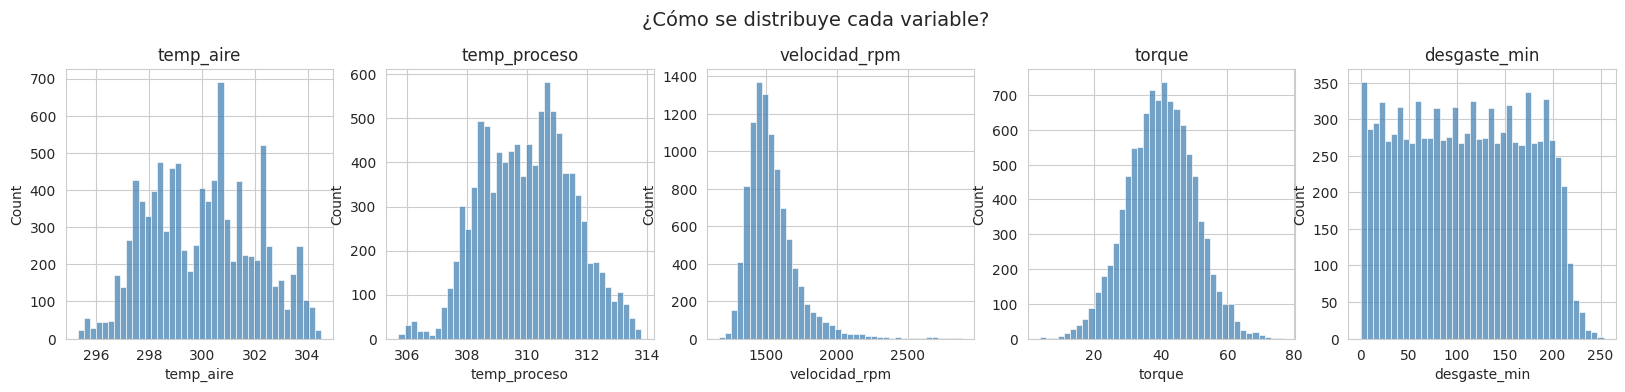

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, var in zip(axes, variables):
    sns.histplot(df[var], bins=40, ax=ax, color="steelblue")
    ax.set_title(var)
plt.suptitle("¿Cómo se distribuye cada variable?", y=1.05, fontsize=14)
plt.show()

- **Temperaturas y torque:** Distribución aproximadamente normal. La mayoría de datos está cerca del promedio.
- **Velocidad:** Distribución unimodal con asimetría positiva (sesgo a la derecha), con moda alrededor de 1500 rpm.
- **Desgaste:** Distribución uniforme. Hay herramientas nuevas y gastadas en proporciones parecidas.

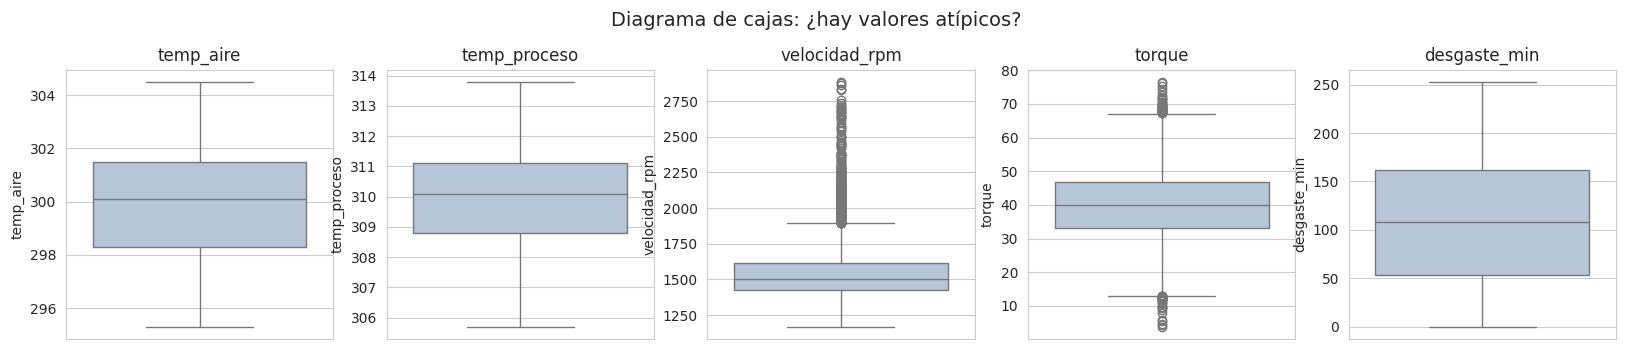

,variable,n_atípicos,tasa_falla_en_atípicos_%,asimetría
0,temp_aire,0,NaN,0.11
1,temp_proceso,0,NaN,0.02
2,velocidad_rpm,418,8.4,1.99
3,torque,69,89.9,-0.01
4,desgaste_min,0,NaN,0.03


In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, var in zip(axes, variables):
    sns.boxplot(y=df[var], ax=ax, color="lightsteelblue")
    ax.set_title(var)
plt.suptitle("Diagrama de cajas: ¿hay valores atípicos?", y=1.05, fontsize=14)
plt.show()

# Regla del rango intercuartílico (RIC):
filas = []
for var in variables:
    q1, q3 = df[var].quantile([0.25, 0.75])
    ric = q3 - q1
    atipico = (df[var] < q1 - 1.5 * ric) | (df[var] > q3 + 1.5 * ric) #Dato atipico
    filas.append({"variable": var,
                  "n_atípicos": atipico.sum(),
                  "tasa_falla_en_atípicos_%": round(df.loc[atipico, "falla"].mean() * 100, 1) if atipico.any() else None,
                  "asimetría": round(df[var].skew(), 2)})
pd.DataFrame(filas)

- Las temperaturas y el desgaste no tienen atípicos.
- La velocidad tiene  atípicos (todos por arriba, velocidades muy altas).
- El torque rambién tiene datos atípicos.

No eliminamos los datos atípicos. No son errores de medición: son justo las situaciones extremas donde la máquina falla. Si los borráramos, borraríamos lo que queremos encontrar.



### 4.4 La base en el tiempo
Exploramos cómo se mueven algunas variables a lo largo del tiempo.

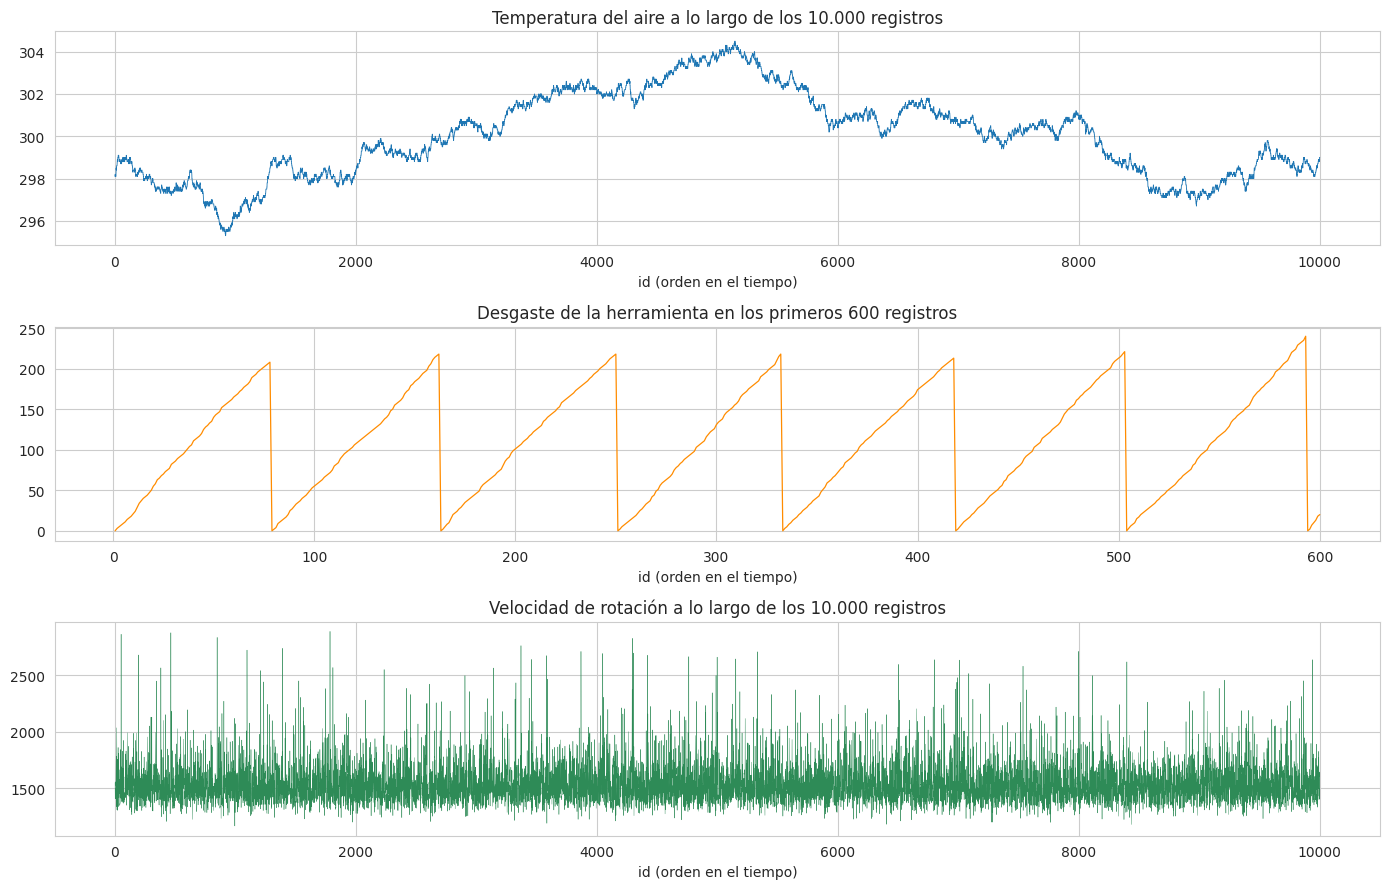

In [ ]:
# La columna "id" está en orden: cada registro ocurre después del anterior.

fig, axes = plt.subplots(3, 1, figsize=(14, 9))
axes[0].plot(df["id"], df["temp_aire"], lw=0.6)
axes[0].set_title("Temperatura del aire a lo largo de los 10.000 registros")
axes[1].plot(df["id"][:600], df["desgaste_min"][:600], lw=0.9, color="darkorange")
axes[1].set_title("Desgaste de la herramienta en los primeros 600 registros")
axes[2].plot(df["id"], df["velocidad_rpm"], lw=0.3, color="seagreen")
axes[2].set_title("Velocidad de rotación a lo largo de los 10.000 registros")
for ax in axes: ax.set_xlabel("id (orden en el tiempo)")
plt.tight_layout(); plt.show()

Cada variable se comporta de forma distinta en el tiempo:
- **Temperatura del aire (arriba):** sube y baja **lentamente**. No salta de un registro al siguiente.
- **Desgaste (centro):** tiene forma de "dientes de sierra". Sube poco a poco mientras la herramienta se usa y, al llegar a unos 200–240 minutos, cae a 0: ahí se cambió la herramienta por una nueva.
- **Velocidad (abajo):** salta al azar de un registro a otro, con picos ocasionales muy altos.



### 4.5 Tipos de fallas en las máquinas.

Máquinas con falla: 339 de 10000 (3.4%)

Fallas por tipo:
falla_calor            115
falla_sobreesfuerzo     98
falla_potencia          95
falla_desgaste          46
falla_aleatoria         19
dtype: int64


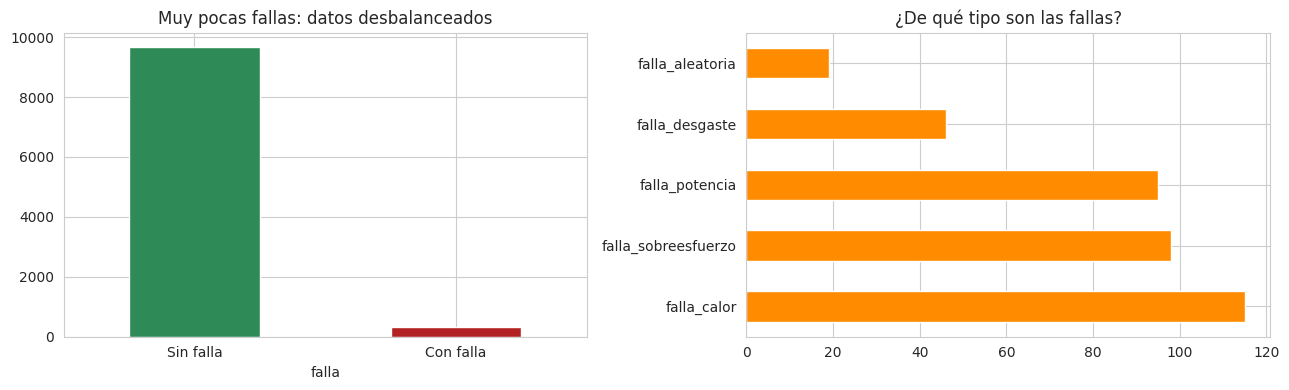

In [ ]:
tipos_falla = ["falla_desgaste", "falla_calor", "falla_potencia", "falla_sobreesfuerzo", "falla_aleatoria"]

print("Máquinas con falla:", df["falla"].sum(), "de", len(df),
      f"({df['falla'].mean()*100:.1f}%)\n")

conteo = df[tipos_falla].sum().sort_values(ascending=False)
print("Fallas por tipo:")
print(conteo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["falla"].value_counts().rename({0: "Sin falla", 1: "Con falla"}).plot.bar(ax=axes[0], color=["seagreen", "firebrick"])
axes[0].set_title("Muy pocas fallas: datos desbalanceados"); axes[0].tick_params(axis="x", rotation=0)
conteo.plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("¿De qué tipo son las fallas?")
plt.tight_layout(); plt.show()

- Solo 339 de 10.000 registros (3,4%) tienen falla. Los datos están **muy desbalanceados**: por cada máquina que falla hay unas 29 que no. Las fallas son raras, y por eso tiene sentido buscarlas como "anomalías".
- Los tipos más comunes son calor (115), sobreesfuerzo (98) y potencia (95). Después vienen desgaste (46) y aleatoria (19).

In [ ]:
# ¿Una misma máquina puede tener varios tipos de falla a la vez?
# Contamos, entre las máquinas con falla, cuántas veces aparecen dos tipos juntos.
con_falla = df[df["falla"] == 1][tipos_falla]
coocurrencia = con_falla.T.dot(con_falla)
coocurrencia.index = coocurrencia.columns = [t.replace("falla_", "") for t in tipos_falla]
coocurrencia

,desgaste,calor,potencia,sobreesfuerzo,aleatoria
desgaste,46,0,1,3,1
calor,0,115,3,6,0
potencia,1,3,95,12,0
sobreesfuerzo,3,6,12,98,0
aleatoria,1,0,0,0,1


Son pocas las máquinas que presentan fallas ocasionadas por distintos tipos, pero la combinación más común es sobreesfuerzo + potencia (12 máquinas). Tiene sentido: ambas tienen que ver con hacer demasiada fuerza.



### 4.6 La calidad del producto

In [ ]:
tabla_calidad = df.groupby("calidad")["falla"].agg(["count", "sum", "mean"])
tabla_calidad.columns = ["n_registros", "n_fallas", "tasa_falla"]
tabla_calidad["tasa_falla"] = (tabla_calidad["tasa_falla"] * 100).round(2)
tabla_calidad.loc[["L", "M", "H"]]

,n_registros,n_fallas,tasa_falla
calidad,,,
L,6000,235,3.92
M,2997,83,2.77
H,1003,21,2.09


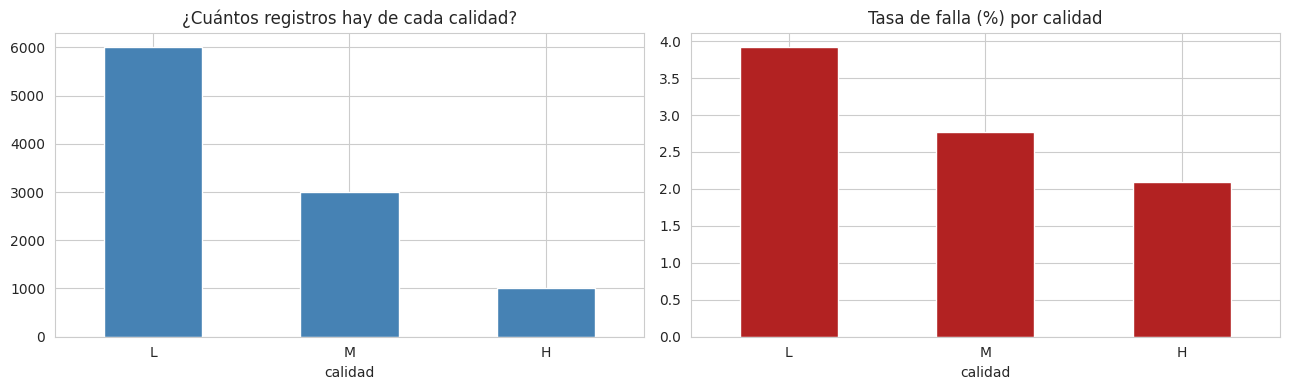

Promedio de cada sensor según la calidad:
         temp_aire  temp_proceso  velocidad_rpm  torque  desgaste_min
calidad                                                              
L            300.0         310.0         1539.5    40.0         108.4
M            300.0         310.0         1537.6    40.0         107.3
H            299.9         309.9         1538.1    39.8         107.4

Tipos de falla según la calidad:
         falla_desgaste  falla_calor  falla_potencia  falla_sobreesfuerzo  \
calidad                                                                     
L                    25           76              59                   87   
M                    14           31              31                    9   
H                     7            8               5                    2   

         falla_aleatoria  
calidad                   
L                     13  
M                      2  
H                      4  


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["calidad"].value_counts().loc[["L", "M", "H"]].plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("¿Cuántos registros hay de cada calidad?"); axes[0].tick_params(axis="x", rotation=0)
(df.groupby("calidad")["falla"].mean().loc[["L", "M", "H"]] * 100).plot.bar(ax=axes[1], color="firebrick")
axes[1].set_title("Tasa de falla (%) por calidad"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("Promedio de cada sensor según la calidad:")
print(df.groupby("calidad")[variables].mean().loc[["L", "M", "H"]].round(1))
print("\nTipos de falla según la calidad:")
print(df.groupby("calidad")[tipos_falla].sum().loc[["L", "M", "H"]])

- La mayoría de los registros son de calidad L (60%), luego M (30%) y H (10%).
- La calidad L falla más (3,9%) que la M (2,8%) y la H (2,1%).
- Los sensores son prácticamente iguales en las tres calidades: mismas temperaturas, velocidad, torque y desgaste promedio.
- Entonces, ¿por qué falla más la L? Por el sobreesfuerzo: 87 de las 98 fallas de ese tipo son de calidad L.

Como la calidad es una categoría y no cambia los sensores, no la usamos dentro del clustering. La dejamos para describir.



### 4.7 Correlación entre las variables.


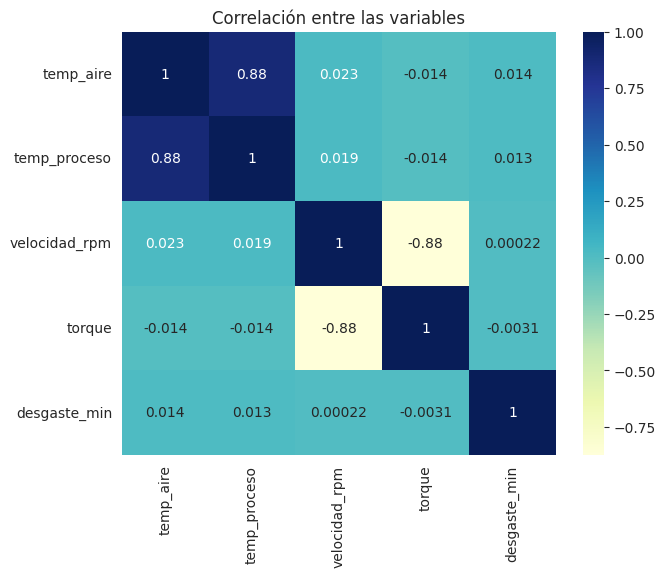

In [ ]:
plt.figure(figsize=(7, 5.5))
dataplot = sns.heatmap(df[variables].corr(), cmap="YlGnBu", annot=True)
plt.title("Correlación entre las variables")
plt.show()

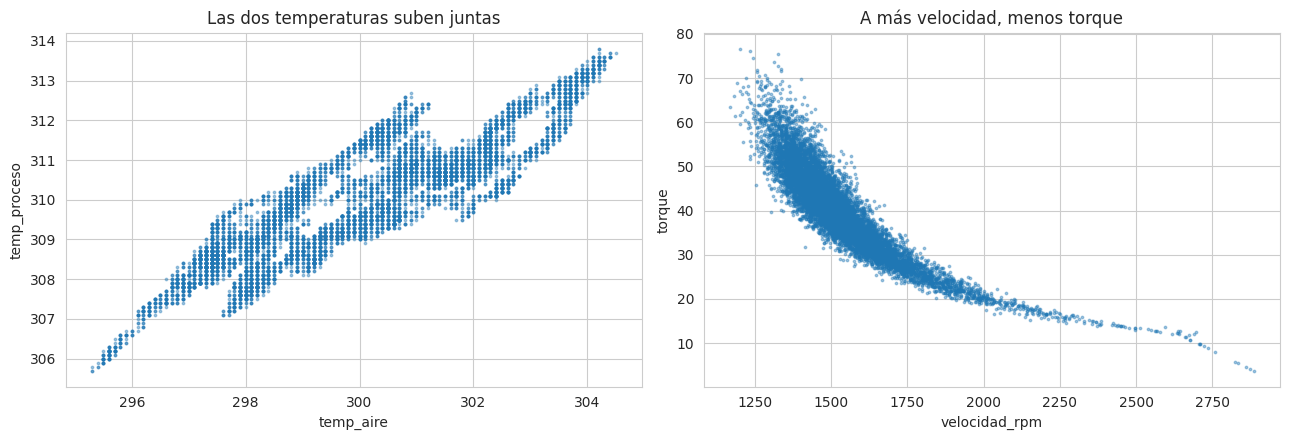

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["temp_aire"], df["temp_proceso"], s=3, alpha=0.4)
axes[0].set_xlabel("temp_aire"); axes[0].set_ylabel("temp_proceso")
axes[0].set_title("Las dos temperaturas suben juntas")
axes[1].scatter(df["velocidad_rpm"], df["torque"], s=3, alpha=0.4)
axes[1].set_xlabel("velocidad_rpm"); axes[1].set_ylabel("torque")
axes[1].set_title("A más velocidad, menos torque")
plt.tight_layout(); plt.show()


- Las dos temperaturas tienen alta correlación (correlación 0,88). Si el ambiente está caliente, la máquina también.
- La velocidad y el torque tienen correlación inversa (−0,88).
- El desgaste no presenta correlación con las demás variables.
- Entre los dos bloques (temperaturas contra velocidad y torque) no hay relación.

Entonces, aunque tenemos 5 variables, en el fondo hay 3 "ideas": **temperatura**, **mecánica** (velocidad contra torque) y **desgaste**. El PCA debería confirmarlo.



### 4.8 Relación de las variables con las fallas.

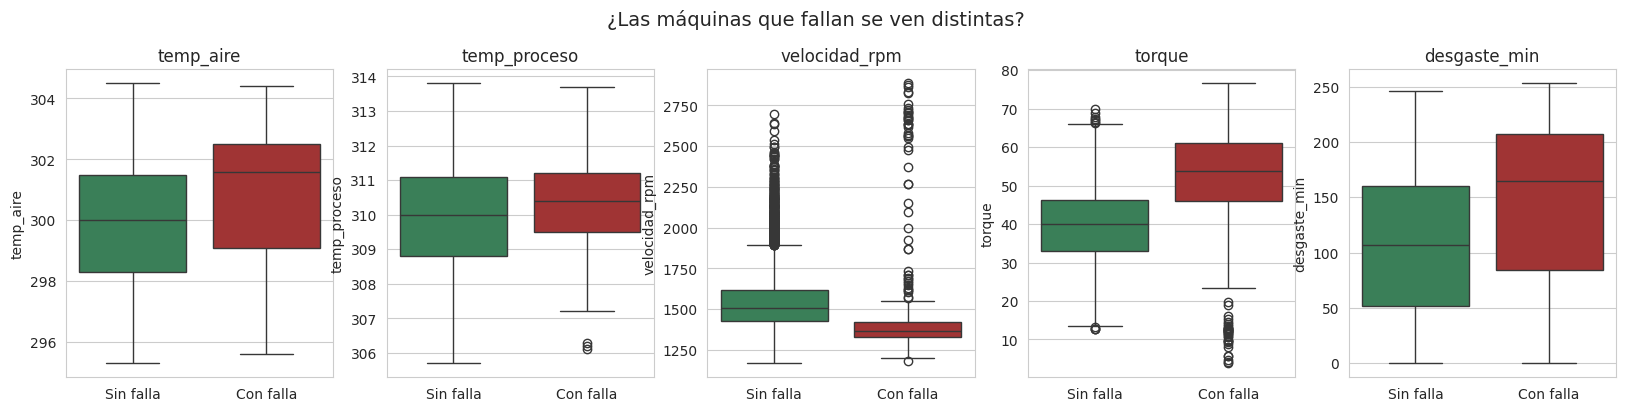

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, var in zip(axes, variables):
    sns.boxplot(data=df, x="falla", y=var, ax=ax, palette=["seagreen", "firebrick"])
    ax.set_xticklabels(["Sin falla", "Con falla"]); ax.set_xlabel("")
    ax.set_title(var)
plt.suptitle("¿Las máquinas que fallan se ven distintas?", y=1.03, fontsize=14)
plt.show()

Las cajas rojas (con falla) están corridas hacia los extremos: más torque más desgaste y temperatura del aire algo más alta. En velocidad tienen más puntos tanto muy abajo como muy arriba.

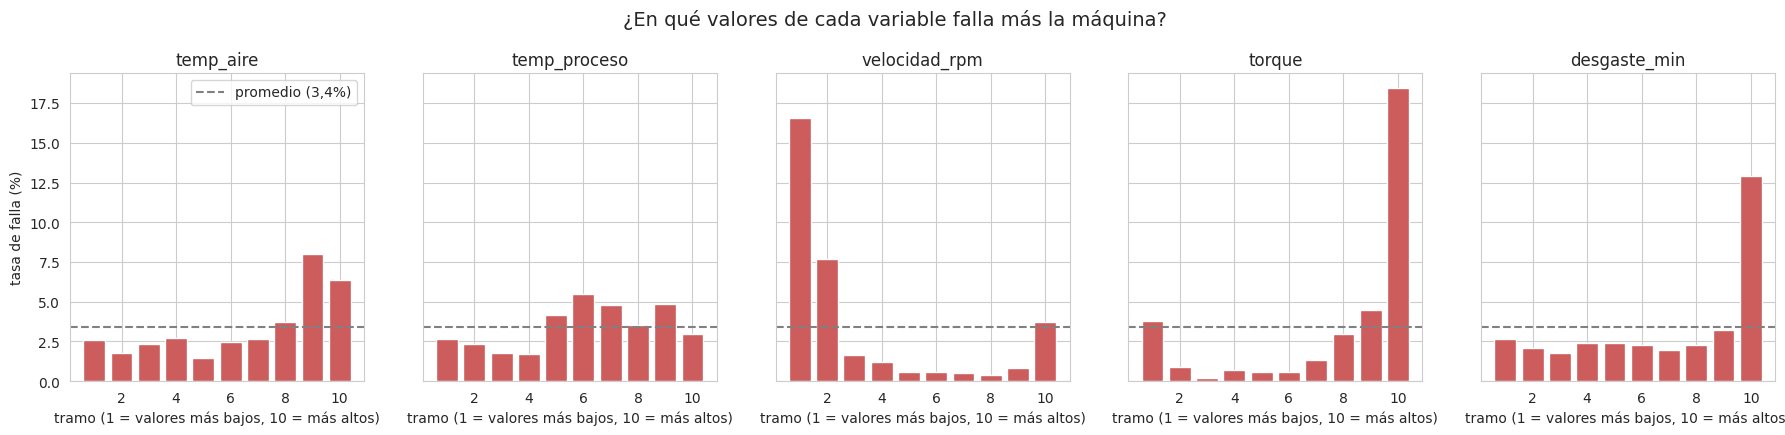

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, var in zip(axes, variables):
    tramos = pd.qcut(df[var], 10)
    tasa = df.groupby(tramos, observed=True)["falla"].mean() * 100
    ax.bar(range(1, 11), tasa.values, color="indianred")
    ax.axhline(df["falla"].mean() * 100, ls="--", color="gray", label="promedio (3,4%)")
    ax.set_title(var); ax.set_xlabel("tramo (1 = valores más bajos, 10 = más altos)")
axes[0].set_ylabel("tasa de falla (%)"); axes[0].legend()
plt.suptitle("¿En qué valores de cada variable falla más la máquina?", y=1.04, fontsize=14)
plt.show()

*(la línea punteada es el promedio general, 3,4%)*
- **Velocidad:** Distribución bimodal. En el tramo de velocidades más bajas falla el **16,5%** de las máquinas, en el centro casi nada (menos del 1%) y en el tramo más alto sube otra vez (3,7%).
- **Torque:** también presenta distribución bimodal, aún más marcada a la derecha: en el tramo de más fuerza falla el **18,5%**.
- **Desgaste:** plano hasta que, en el último tramo (herramienta más gastada), salta al **12,9%**.
- **Temperatura del aire:** en los dos tramos más calientes falla el 8,0% y el 6,4%.

En conclusión: la máquina falla en los extremos, no en el centro. Por eso tiene sentido usar métodos que busquen lo "raro" o lo que está en las orillas de los datos.



### 4.9 Las "reglas físicas" detrás de cada falla
Según la documentación de la base, cada tipo de falla ocurre cuando se cumple una regla física. Creamos tres variables para visualizar este comportamiento:
- **Diferencia de temperatura** = temperatura del proceso − temperatura del aire: cuánto se calienta la máquina por encima del ambiente.
- **Potencia** = torque × velocidad (convertida a vatios): cuánta energía usa.
- **Esfuerzo** = desgaste × torque: hacer fuerza con una herramienta gastada.

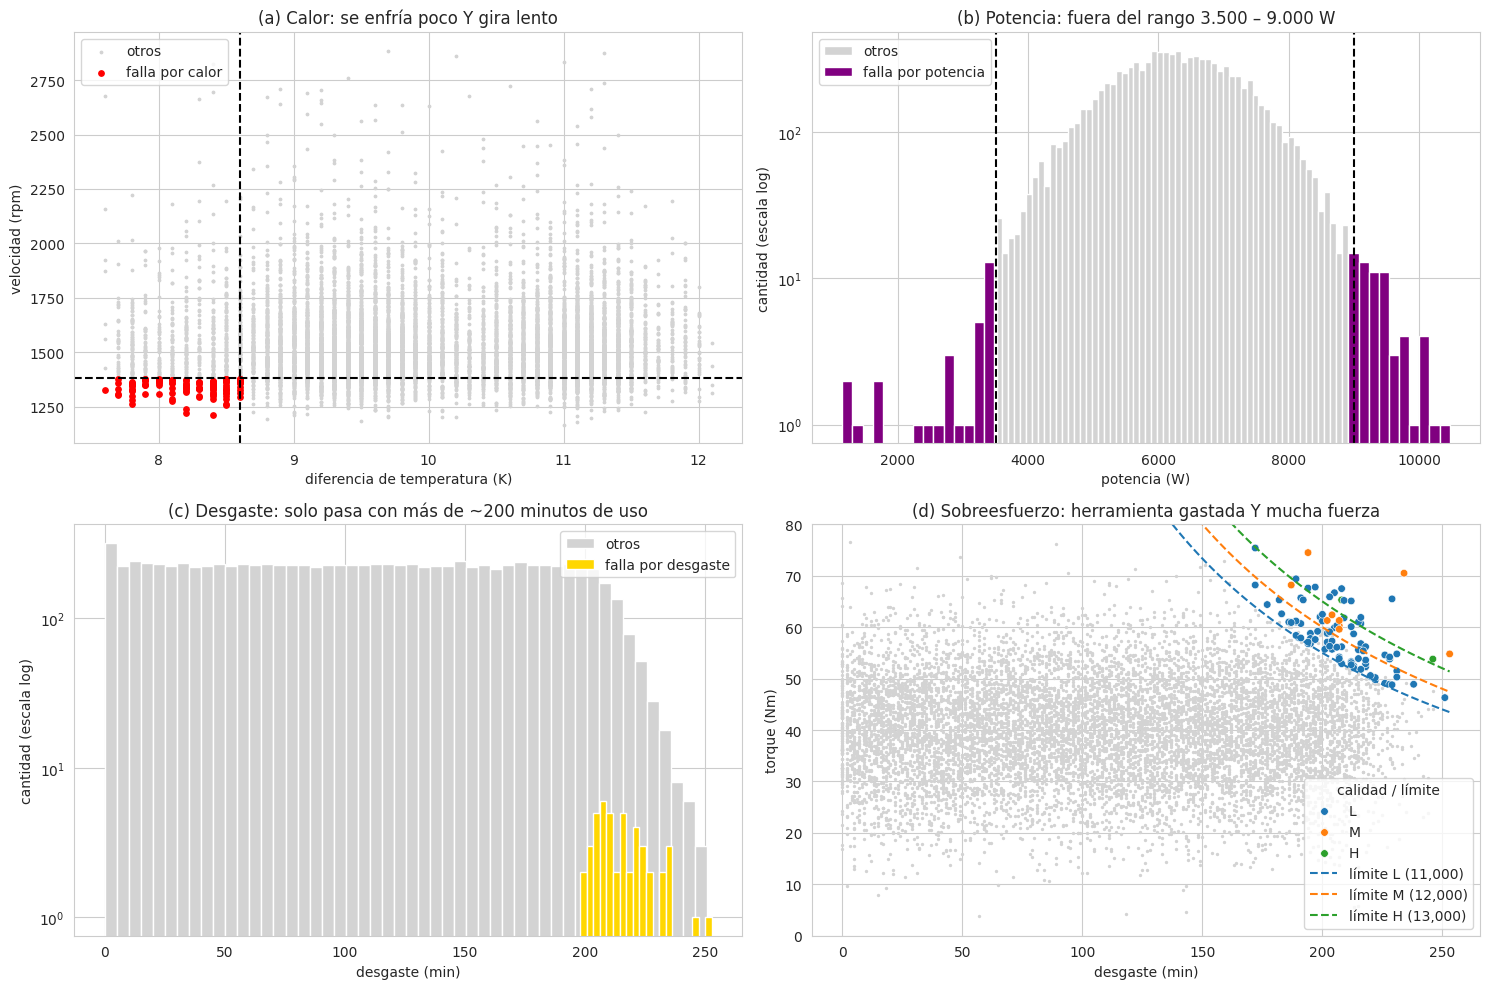

Fallas por calor: diferencia de temperatura máxima = 8.6 K | velocidad máxima = 1379 rpm
Máquinas SIN falla: potencia entre 3515 y 8998 W
Fallas por desgaste: desgaste entre 198 y 253 min


In [ ]:
# Creamos tres variables "físicas" SOLO para entender las fallas (no entran a los modelos).
dif_temp = df["temp_proceso"] - df["temp_aire"]                       # cuánto se calienta la máquina sobre el ambiente
potencia = df["torque"] * df["velocidad_rpm"] * 2 * np.pi / 60         # potencia en vatios (W) [2*pi/60 = factor de conversión]
esfuerzo = df["desgaste_min"] * df["torque"]                           # herramienta gastada x fuerza

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) Calor: poca diferencia de temperatura + velocidad baja
ax = axes[0, 0]
ax.scatter(dif_temp, df["velocidad_rpm"], s=3, c="lightgray", label="otros")
m = df["falla_calor"] == 1
ax.scatter(dif_temp[m], df.loc[m, "velocidad_rpm"], s=15, c="red", label="falla por calor")
ax.axvline(8.6, ls="--", color="k"); ax.axhline(1380, ls="--", color="k")
ax.set_xlabel("diferencia de temperatura (K)"); ax.set_ylabel("velocidad (rpm)")
ax.set_title("(a) Calor: se enfría poco Y gira lento"); ax.legend()

# (b) Potencia: muy baja o muy alta
ax = axes[0, 1]
ax.hist(potencia[df["falla_potencia"] == 0], bins=60, color="lightgray", label="otros")
ax.hist(potencia[df["falla_potencia"] == 1], bins=60, color="purple", label="falla por potencia")
ax.axvline(3500, ls="--", color="k"); ax.axvline(9000, ls="--", color="k")
ax.set_yscale("log"); ax.set_xlabel("potencia (W)"); ax.set_ylabel("cantidad (escala log)")
ax.set_title("(b) Potencia: fuera del rango 3.500 – 9.000 W"); ax.legend()

# (c) Desgaste: herramienta muy usada
ax = axes[1, 0]
ax.hist(df.loc[df["falla_desgaste"] == 0, "desgaste_min"], bins=50, color="lightgray", label="otros")
ax.hist(df.loc[df["falla_desgaste"] == 1, "desgaste_min"], bins=20, color="gold", label="falla por desgaste")
ax.set_yscale("log"); ax.set_xlabel("desgaste (min)"); ax.set_ylabel("cantidad (escala log)")
ax.set_title("(c) Desgaste: solo pasa con más de ~200 minutos de uso"); ax.legend()

# (d) Sobreesfuerzo: desgaste x torque alto (el límite depende de la calidad)
ax = axes[1, 1]
for cal, color in zip(["L", "M", "H"], ["tab:blue", "tab:orange", "tab:green"]):
    sub = df["calidad"] == cal
    ax.scatter(df.loc[sub, "desgaste_min"], df.loc[sub, "torque"], s=2, c="lightgray")
m = df["falla_sobreesfuerzo"] == 1
sns.scatterplot(x=df.loc[m, "desgaste_min"], y=df.loc[m, "torque"], hue=df.loc[m, "calidad"],
                hue_order=["L", "M", "H"], s=30, ax=ax)
x = np.linspace(60, 253, 100)
for lim, color, cal in [(11000, "tab:blue", "L"), (12000, "tab:orange", "M"), (13000, "tab:green", "H")]:
    ax.plot(x, lim / x, ls="--", color=color, label=f"límite {cal} ({lim:,})")
ax.set_ylim(0, 80); ax.set_xlabel("desgaste (min)"); ax.set_ylabel("torque (Nm)")
ax.set_title("(d) Sobreesfuerzo: herramienta gastada Y mucha fuerza"); ax.legend(title="calidad / límite")

plt.tight_layout(); plt.show()

print("Fallas por calor: diferencia de temperatura máxima =", round(dif_temp[df['falla_calor'] == 1].max(), 1),
      "K | velocidad máxima =", df.loc[df['falla_calor'] == 1, 'velocidad_rpm'].max(), "rpm")
print("Máquinas SIN falla: potencia entre", round(potencia[df['falla'] == 0].min()), "y", round(potencia[df['falla'] == 0].max()), "W")
print("Fallas por desgaste: desgaste entre", df.loc[df['falla_desgaste'] == 1, 'desgaste_min'].min(),
      "y", df.loc[df['falla_desgaste'] == 1, 'desgaste_min'].max(), "min")

Cada tipo de falla tiene su "zona de peligro" bien definida:
- **(a) Calor:** todas las fallas (rojo) están en la esquina de abajo a la izquierda. La máquina está menos de 8,6 grados más caliente que el aire (se enfría mal) y gira a menos de 1.380 rpm. Las dos condiciones tienen que darse al tiempo.
- **(b) Potencia:** las máquinas sin falla están todas entre unos 3.500 y 9.000 W. Las fallas (morado) están por fuera de ese rango: muy poca potencia o demasiada.
- **(c) Desgaste:** solo ocurren con herramientas de más de ~200 minutos de uso (entre 198 y 253 minutos).
- **(d) Sobreesfuerzo:** ocurren cuando desgaste × torque supera un límite que depende de la calidad: 11.000 para L, 12.000 para M y 13.000 para H. Por eso la calidad L falla más: aguanta menos.

Las fallas por potencia ocurren en valores extremos de una sola variable, así que deberían ser fáciles de detectar como "raras". En cambio, las de calor y sobreesfuerzo dependen de combinaciones de valores que, por separado, son normales. Por ejemplo, una velocidad de 1.300 rpm no es rara, ni una diferencia de 8,5 grados; lo peligroso es tener las dos a la vez. Esas serán más difíciles de detectar para los métodos no supervisados.



### 4.10 Resumen del EDA

| # | Hallazgo | ¿Qué implica para el proyecto? |
|---|---|---|
| 1 | Base limpia: sin faltantes ni duplicados | No hay que limpiar |
| 2 | Escalas muy distintas (rpm en miles, temperatura en grados) | Hay que **estandarizar** (sección 5) |
| 3 | Atípicos en velocidad y torque, y muchos de ellos son fallas | **No se eliminan**: son la señal que buscamos |
| 4 | Solo 3,4% de fallas | Tiene sentido buscarlas como **anomalías** |
| 5 | Temperaturas juntas, velocidad y torque al revés, desgaste solo | En el fondo hay **3 ideas**, y el PCA debería mostrarlo |
| 6 | La máquina falla en los **extremos** (forma de "U") | Usar un método que detecte lo **raro**: DBSCAN |
| 7 | Cada falla tiene su zona; calor y sobreesfuerzo dependen de combinaciones | Esperamos detectar bien las de potencia y peor las de calor |
| 8 | La calidad no cambia los sensores, pero L aguanta menos esfuerzo | La calidad no entra al clustering; se usa para describir |

## 5. Preparación: estandarizar

Todos los métodos que vamos a usar miden distancias entre puntos. Si no hacemos nada, la velocidad (que varía en cientos de rpm) "pesaría" mucho más que la temperatura (que varía en 1 o 2 grados), solo por la unidad de medida.

Por ello utilizamos `StandardScaler` de scikit-learn (equivale a la función `scale`). A cada variable le resta su promedio ($\mu$) y la divide por su desviación estándar ($\sigma$):

$$Z = \frac{X - \mu}{\sigma}$$

Así todas quedan con promedio 0 y desviación 1, y todas pesan igual.


In [ ]:
X = df[variables]          # solo las 5 variables de sensores

escalador = StandardScaler()                     # creamos el estandarizador
Z = pd.DataFrame(escalador.fit_transform(X),     # fit: calcula promedio y desviación; transform: aplica la fórmula
                 columns=variables, index=X.index)  # le devolvemos los nombres de las columnas
Z.head()

,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min
0,-0.952389,-0.947360,0.068185,0.282200,-1.695984
1,-0.902393,-0.879959,-0.729472,0.633308,-1.648852
2,-0.952389,-1.014761,-0.227450,0.944290,-1.617430
3,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009
4,-0.902393,-0.879959,-0.729472,0.001313,-1.554588


In [ ]:
# Verificamos: ahora cada variable tiene media 0 y desviación estándar 1
Z.describe().round(2).loc[["mean", "std", "min", "max"]]

,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min
mean,-0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.35,-2.90,-2.07,-3.63,-1.70
max,2.25,2.56,7.51,3.67,2.28


Ahora todas las variables tienen media 0 y desviación 1. Los valores máximos muestran que la velocidad tiene puntos muy alejados (hasta 7,5 desviaciones por encima del promedio): son las máquinas que giran muy rápido.


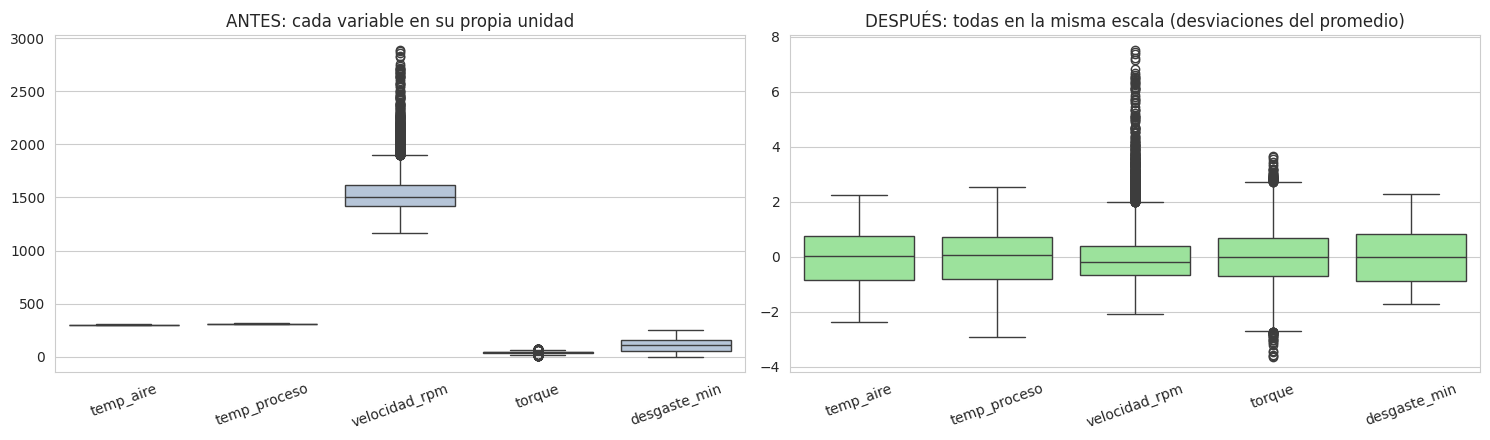

Máquina 1


,valor original,promedio (mean_),desviación (scale_),valor estandarizado (z)
temp_aire,298.1,300.0,2.0,-0.95
temp_proceso,308.6,310.0,1.5,-0.95
velocidad_rpm,1551.0,1538.8,179.3,0.07
torque,42.8,40.0,10.0,0.28
desgaste_min,0.0,108.0,63.7,-1.70


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=X, ax=axes[0], color="lightsteelblue")
axes[0].set_title("ANTES: cada variable en su propia unidad")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=Z, ax=axes[1], color="lightgreen")
axes[1].set_title("DESPUÉS: todas en la misma escala (desviaciones del promedio)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# Ejemplo con una sola máquina: ¿qué significa su valor estandarizado?
print("Máquina", df.loc[0, "id"])
pd.DataFrame({"valor original": X.iloc[0],
              "promedio (mean_)": pd.Series(escalador.mean_, index=variables).round(1),
              "desviación (scale_)": pd.Series(escalador.scale_, index=variables).round(1),
              "valor estandarizado (z)": Z.iloc[0].round(2)})

- **Antes (izquierda):** la caja de la velocidad (en miles) aplasta a todas las demás, que casi no se ven. Para un algoritmo que mide distancias, solo "existiría" la velocidad.
- **Después (derecha):** todas las cajas tienen el mismo tamaño y están centradas en 0. Ahora las 5 variables pesan igual.



## 6. PCA

Utilizamos la librería PCA de scikit-learn para obtener el PCA de los datos normalizados de los sensores.




### 6.1 ¿Cuánta información guarda cada componente?

In [ ]:
pca = PCA()                     # sin n_components: calcula los 5 componentes
pca.fit(Z)                      # aprende las direcciones a partir de los datos estandarizados

# Proporción de varianza explicada por cada componente
prop = pca.explained_variance_ratio_
varianza = pd.DataFrame({
    "componente": [f"CP{i+1}" for i in range(len(variables))],
    "valor propio": pca.explained_variance_.round(3),     # para el criterio de Kaiser
    "% varianza": (prop * 100).round(1),
    "% acumulado": (np.cumsum(prop) * 100).round(1),
})
varianza

,componente,valor propio,% varianza,% acumulado
0,CP1,1.911,38.2,38.2
1,CP2,1.841,36.8,75.0
2,CP3,1.000,20.0,95.0
3,CP4,0.126,2.5,97.5
4,CP5,0.123,2.5,100.0


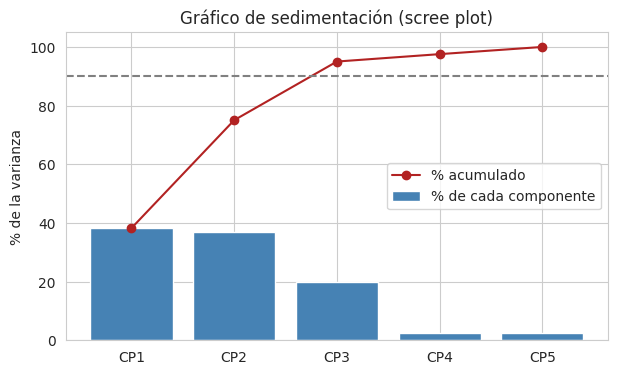

In [ ]:
# Gráfico de sedimentación
prop = pca.explained_variance_ratio_
x = range(1, len(variables) + 1)
plt.figure(figsize=(7, 4))
plt.bar(x, prop*100, color="steelblue", label="% de cada componente")
plt.plot(x, np.cumsum(prop)*100, "o-", color="firebrick", label="% acumulado")
plt.axhline(90, ls="--", color="gray")
plt.xticks(x, [f"CP{i}" for i in x]); plt.ylabel("% de la varianza")
plt.title("Gráfico de sedimentación (scree plot)")
plt.legend(); plt.show()

- La matriz de covarianzas (como los datos están estandarizados, es igual a la de correlaciones) muestra los dos pares que vimos en el EDA: temperaturas (0,88) y velocidad contra torque (−0,88).
- CP1 guarda el 38,2%, CP2 el 36,8% y CP3 el 20,0%. **Con 3 componentes conservamos el 95% de la información**
- CP4 y CP5 aportan solo 2,5% cada uno, casi nada. En el gráfico de sedimentación, el "codo" está después de CP3.
- **Criterio de Kaiser**: quedarse con los componentes con valor propio mayor que 1. Aquí son CP1 (1,91), CP2 (1,84) y CP3 (1,00) **3 componentes**.


### 6.2 ¿Qué significa cada componente? (loadings)

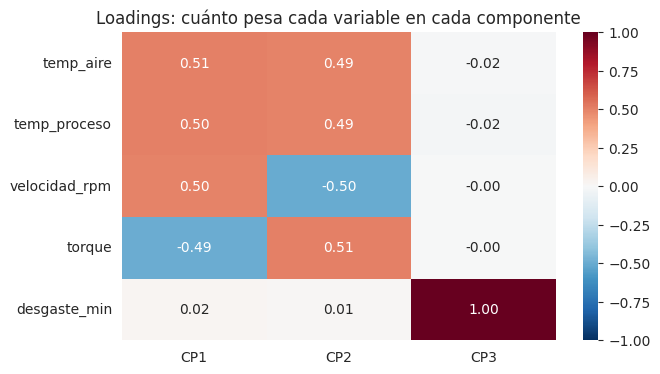

In [ ]:
# Loadings: cada columna es un vector propio (cuánto pesa cada variable en cada componente)
loadings = pd.DataFrame(pca.components_.T, index=variables,
                        columns=[f"CP{i+1}" for i in range(len(variables))])
plt.figure(figsize=(7, 4))
sns.heatmap(loadings.iloc[:, :3], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Loadings: cuánto pesa cada variable en cada componente")
plt.show()

Los loadings dicen cuánto pesa cada variable en cada componente:
- **CP3 = desgaste**, puro (loading 1,00)
- **CP1 y CP2 mezclan temperatura y mecánica.** Ambos tienen las dos temperaturas con signo positivo, pero difieren en la mecánica: CP1 sube con la **velocidad** y CP2 sube con el **torque**.

Ahora calculamos las coordenadas de cada máquina en los componentes (datos estandarizados × loadings) y dibujamos el **biplot**

In [ ]:
# Coordenadas de cada máquina en los componentes: datos estandarizados x loadings
componentes = Z.dot(loadings)
df["CP1"], df["CP2"], df["CP3"] = componentes["CP1"], componentes["CP2"], componentes["CP3"]
componentes.head()

,CP1,CP2,CP3,CP4,CP5
0,-1.093847,-0.854210,-1.666416,0.197043,-0.152443
1,-1.602678,-0.215765,-1.618869,-0.062187,0.028707
2,-1.599406,-0.401641,-1.586248,0.433182,-0.270257
3,-1.230438,-0.664604,-1.555071,-0.339764,0.297282
4,-1.289814,-0.535153,-1.524319,-0.418906,0.297448


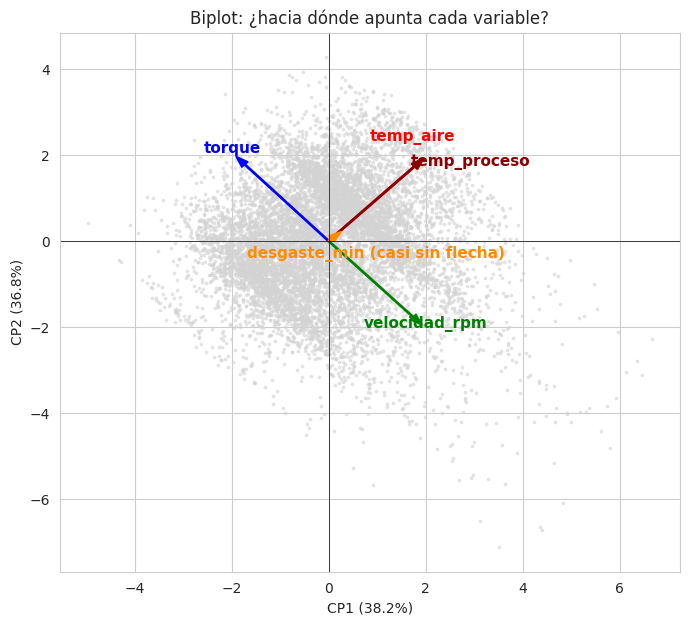

In [ ]:
# Biplot: la nube de puntos + una flecha por variable.
# La flecha muestra hacia dónde crece esa variable dentro del plano CP1-CP2.
plt.figure(figsize=(8, 7))
plt.scatter(df["CP1"], df["CP2"], s=3, c="lightgray", alpha=0.5)
escala = 3.5
colores_flecha = ["red", "darkred", "green", "blue", "darkorange"]
for var, col in zip(variables, colores_flecha):
    x, y = loadings.loc[var, "CP1"] * escala, loadings.loc[var, "CP2"] * escala
    plt.arrow(0, 0, x, y, color=col, width=0.03, head_width=0.18)
    desplazamiento = {"temp_aire": (-0.3, 0.35), "temp_proceso": (0.9, -0.25),
                      "desgaste_min": (0.9, -0.45)}.get(var, (0, 0))
    etiqueta = var + (" (casi sin flecha)" if var == "desgaste_min" else "")
    plt.text(x * 1.15 + desplazamiento[0], y * 1.15 + desplazamiento[1], etiqueta,
             color=col, fontsize=11, ha="center", fontweight="bold")
plt.axhline(0, color="k", lw=0.5); plt.axvline(0, color="k", lw=0.5)
plt.xlabel(f"CP1 ({prop[0]*100:.1f}%)"); plt.ylabel(f"CP2 ({prop[1]*100:.1f}%)")
plt.title("Biplot: ¿hacia dónde apunta cada variable?")
plt.show()

Cada flecha apunta hacia donde crece esa variable dentro del plano:
- Las flechas de temp_aire y temp_proceso están una encima de la otra, como van juntas, apuntan en la misma dirección (correlación alta positiva).
- **velocidad_rpm** y **torque** apuntan en direcciones opuestas, cuando una sube, la otra baja (correlación alta negativa).
- **desgaste_min** casi no tiene flecha, no vive en este plano, sino en CP3
.



### 6.3 Los datos en el plano PCA

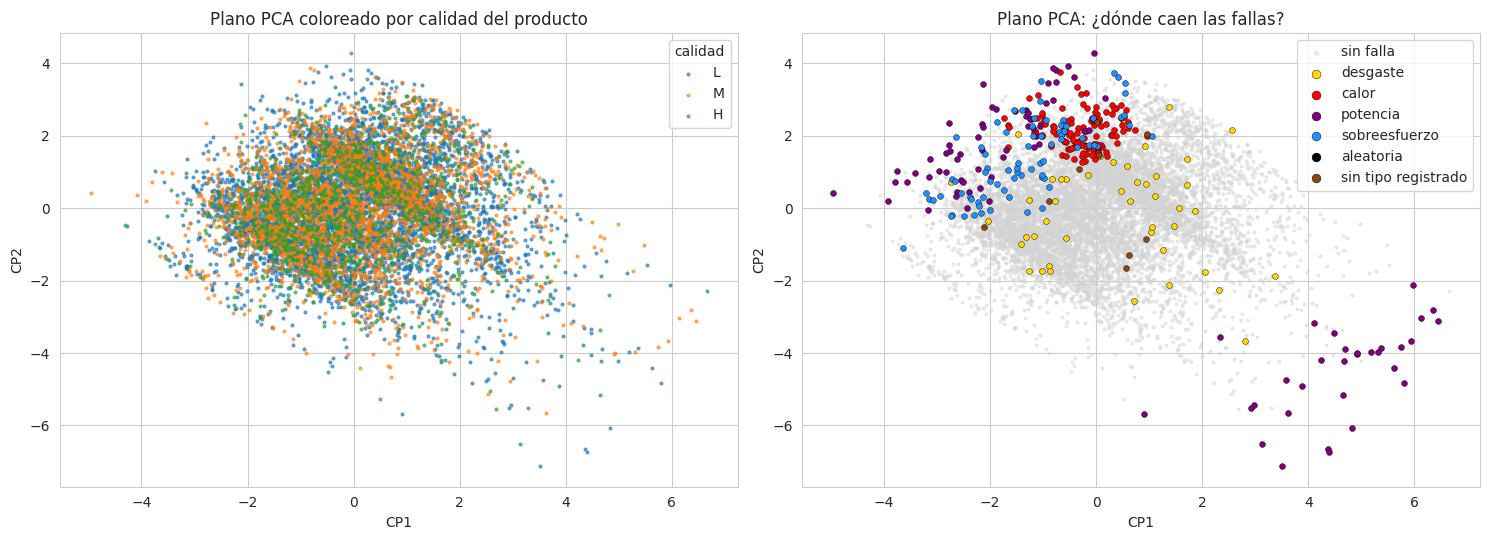

In [ ]:
# Para ver dónde están las fallas, ponemos un nombre al tipo de falla de cada registro
def nombre_falla(fila):
    if fila["falla"] == 0:
        return "sin falla"
    for t in tipos_falla:
        if fila[t] == 1:
            return t.replace("falla_", "")
    return "sin tipo registrado"
df["tipo_falla"] = df.apply(nombre_falla, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for cal, col in zip(["L", "M", "H"], ["tab:blue", "tab:orange", "tab:green"]):
    sub = df[df["calidad"] == cal]
    axes[0].scatter(sub["CP1"], sub["CP2"], s=4, alpha=0.6, c=col, label=cal)
axes[0].legend(title="calidad"); axes[0].set_title("Plano PCA coloreado por calidad del producto")

orden_fallas = ["desgaste", "calor", "potencia", "sobreesfuerzo", "aleatoria", "sin tipo registrado"]
colores_fallas = ["gold", "red", "purple", "dodgerblue", "black", "saddlebrown"]
sin = df[df["tipo_falla"] == "sin falla"]
axes[1].scatter(sin["CP1"], sin["CP2"], s=4, c="lightgray", alpha=0.4, label="sin falla")
for t, c in zip(orden_fallas, colores_fallas):
    sub = df[df["tipo_falla"] == t]
    axes[1].scatter(sub["CP1"], sub["CP2"], s=18, c=c, label=t, edgecolor="k", linewidth=0.3)
axes[1].legend(markerscale=1.5); axes[1].set_title("Plano PCA: ¿dónde caen las fallas?")
for ax in axes: ax.set_xlabel("CP1"); ax.set_ylabel("CP2")
plt.tight_layout(); plt.show()

- **En la gráfica de la izquierda:** las tres calidades (L, M, H) están completamente mezcladas. La calidad del producto no separa los datos.
- **En la gráfica de la derecha:** coloreamos por tipo de falla solo para mirar. Las fallas no están al azar:
  - **Calor (rojo):** arriba, en la zona de alta temperatura y velocidad baja.
  - **Potencia (morado):** en las dos puntas del eje mecánico. Abajo a la derecha están las de velocidad muy alta y torque bajo (poca potencia), y a la izquierda las de torque muy alto (demasiada potencia).
  - **Sobreesfuerzo (azul):** arriba a la izquierda, con torque alto.
  - **Desgaste (amarillo):** dispersas en el plano, porque dependen del desgaste, que no se ve en esta gráfica.
  - **Aleatoria:** en cualquier parte, como es de esperar.

**Conclusión del PCA:** con solo dos componentes ya se ve que las fallas viven en las **orillas** de la nube de puntos.

## 7. K-medias (K-means)

### 7.1 Parámetro 1:

In [ ]:
# K-medias empieza con centroides al azar y puede quedarse en un "óptimo local"
# Probamos 5 semillas distintas con 1 solo arranque y con 10 arranques
filas = []
for n_init in [1, 10]:
    inercias = [round(KMeans(n_clusters=3, n_init=n_init, random_state=s).fit(Z).inertia_) for s in range(5)]
    filas.append({"n_init": n_init, "varianza intra clúster con 5 semillas distintas": inercias})
pd.DataFrame(filas)

,n_init,varianza intra clúster con 5 semillas distintas
0,1,"[28306, 28306, 30618, 28306, 28306]"
1,10,"[28306, 28306, 28306, 28306, 28306]"


Con un solo arranque (`n_init=1`), una de las 5 semillas se quedó atascada en una solución peor (30.615 en vez de 28.303).

Con 10 arranques, las 5 semillas llegan siempre a la misma solución. Por eso usamos **`n_init=10`**.



### 7.2 Parámetro 2: ¿cuántos grupos? Método del codo y coeficiente de Silhouette
Evaluamos de 1 a 10 clústeres:
- **Método del codo:** la suma de distancias de cada punto a su centroide. Siempre baja al aumentar *K*; buscamos el punto donde deja de bajar mucho.
- **Coeficiente de Silhouette:** va de −1 a 1 y mide qué tan bien asignado está cada punto a su grupo frente a los otros grupos. Más alto es mejor; por encima de 0,5 se considera una buena separación.

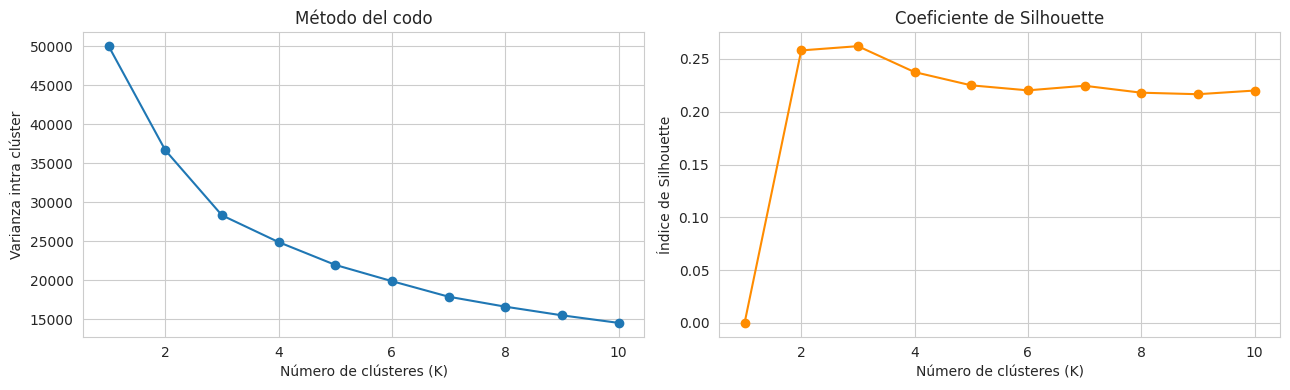

K con mayor Silhouette: 3


,K,varianza intra clúster,silhouette
0,1,50000.0,0.000
1,2,36654.0,0.258
2,3,28306.0,0.262
3,4,24871.0,0.238
4,5,21947.0,0.225
5,6,19862.0,0.220
6,7,17869.0,0.225
7,8,16590.0,0.218
8,9,15481.0,0.217
9,10,14510.0,0.220


In [ ]:
# evaluamos de 1 a 10 clusters
varianza_intra_cluster = []
silhouettes = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    varianza_intra_cluster.append(kmeans.inertia_)
    try:
        silhouette = silhouette_score(Z, kmeans.labels_)
    except:
        silhouette = 0   # El índice de Silhouette sólo se puede calcular cuando K > 1
    silhouettes.append(silhouette)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, 11), varianza_intra_cluster, marker="o")
axes[0].set_xlabel("Número de clústeres (K)"); axes[0].set_ylabel("Varianza intra clúster")
axes[0].set_title("Método del codo")
axes[1].plot(range(1, 11), silhouettes, marker="o", color="darkorange")
axes[1].set_xlabel("Número de clústeres (K)"); axes[1].set_ylabel("Índice de Silhouette")
axes[1].set_title("Coeficiente de Silhouette")
plt.tight_layout(); plt.show()

K = int(np.argmax(silhouettes) + 1)      # el K con mayor Silhouette
print("K con mayor Silhouette:", K)
pd.DataFrame({"K": range(1, 11), "varianza intra clúster": np.round(varianza_intra_cluster),
              "silhouette": np.round(silhouettes, 3)})

- El codo no es muy marcado, la curva baja de forma suave después de K = 3
- La Silhouette es máxima en **K = 3 (0,262)**, casi igual a K = 2 (0,258), y después baja. **Elegimos K = 3**
- Una Silhouette de 0,26 es baja. Significa que no hay grupos naturales bien separados, los grupos que formemos serán "regiones" o regímenes de operación (por ejemplo, "caliente" contra "frío"), no tipos de máquina totalmente distintos.



### 7.3 Modelo con K = 3

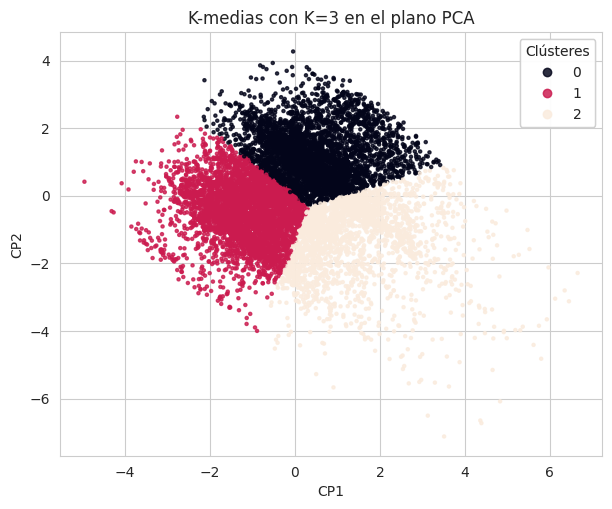

In [ ]:
kmeans_3 = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit_predict(Z)
df["kmeans"] = kmeans_3

# Visualizamos la predicción en el plano PCA
fig, ax = plt.subplots(figsize=(7, 5.5))
g_puntos = plt.scatter(df["CP1"], df["CP2"], c=kmeans_3, alpha=0.8, s=5)
legend = ax.legend(*g_puntos.legend_elements(), loc="upper right", title="Clústeres")
ax.add_artist(legend)
plt.xlabel("CP1"); plt.ylabel("CP2"); plt.title(f"K-medias con K={K} en el plano PCA")
plt.show()

### 7.4 ¿Cómo es cada grupo?
Para describir cada grupo volvemos a las unidades originales y, ahora sí, miramos la tasa de falla de cada uno

In [ ]:
def perfil(columna_grupo):
    """Resume de cada grupo: tamaño, promedio de cada variable y tasa de falla"""
    t = df.groupby(columna_grupo).agg(
        n=("falla", "size"),
        **{v: (v, "mean") for v in variables},
        fallas=("falla", "sum"),
        tasa_falla_pct=("falla", "mean"),
    )
    t["tasa_falla_pct"] = (t["tasa_falla_pct"] * 100).round(1)
    t["veces_el_promedio"] = (t["tasa_falla_pct"] / (df["falla"].mean() * 100)).round(1)
    return t.round(1)

perfil("kmeans")

,n,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min,fallas,tasa_falla_pct,veces_el_promedio
kmeans,,,,,,,,,
0,3926,301.7,311.2,1469.3,43.7,110.4,206,5.2,1.5
1,4014,298.3,308.7,1474.4,43.2,104.8,87,2.2,0.6
2,2060,300.1,310.1,1796.6,26.6,109.5,46,2.2,0.6



| Grupo | Características | Tasa de falla |
|---|---|---|
| **"Caliente"** | **temperatura alta (302 K)**, velocidad normal | **5,2%** |
| "Frío" | temperatura baja (298 K), velocidad normal y torque normal-alto | 2,2% |
| "Rápido" | velocidad alta (~ 1.800 rpm) y torque bajo (~ 27 Nm) | 2,2% |


In [ ]:
# ¿Qué tipos de falla quedan en cada grupo?
df.groupby("kmeans")[tipos_falla].sum()

,falla_desgaste,falla_calor,falla_potencia,falla_sobreesfuerzo,falla_aleatoria
kmeans,,,,,
0,21,115,33,50,11
1,13,0,31,48,5
2,12,0,31,0,3


- Las 115 fallas por calor quedaron en el grupo "caliente". Ninguna en los otros dos.
- El grupo "rápido" tiene 0 fallas por sobreesfuerzo (con poco torque no hay sobreesfuerzo) y concentra fallas de potencia (las de velocidad extrema).
- El sobreesfuerzo se reparte entre "frío" y "caliente", que son los grupos con torque alto.



### 7.5 ¿Y con más grupos? (K = 6, para ver más detalle)

K = 3 es el mejor según la Silhouette, pero los grupos son muy grandes. Como ejercicio descriptivo pedimos 6 grupos para "hacer zoom". Su Silhouette (0,22) es apenas un poco menor, así que la división es razonable.

In [ ]:
# Con más grupos
kmeans_6 = KMeans(n_clusters=6, n_init=10, random_state=SEMILLA).fit_predict(Z)
df["kmeans6"] = kmeans_6
tabla6 = perfil("kmeans6").sort_values("tasa_falla_pct", ascending=False)
tabla6

,n,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min,fallas,tasa_falla_pct,veces_el_promedio
kmeans6,,,,,,,,,
4,2117,301.6,311.1,1477.3,43.0,165.3,133,6.3,1.9
2,1611,298.2,308.7,1463.9,44.0,169.0,65,4.0,1.2
1,1011,301.1,310.8,1894.1,23.8,115.4,37,3.7,1.1
3,1967,301.8,311.3,1488.6,42.2,53.1,67,3.4,1.0
0,1665,298.6,309.0,1420.3,47.7,55.7,32,1.9,0.6
5,1629,298.3,308.8,1653.9,31.6,88.2,5,0.3,0.1


In [ ]:
df.groupby("kmeans6")[tipos_falla].sum().loc[tabla6.index]

,falla_desgaste,falla_calor,falla_potencia,falla_sobreesfuerzo,falla_aleatoria
kmeans6,,,,,
4,24,57,16,50,7
2,14,0,9,48,4
1,7,0,30,0,0
3,0,55,10,0,6
0,0,3,29,0,0
5,1,0,1,0,2


*(ordenados de más a menos riesgoso)* Ahora aparecen las **tres ideas** del PCA, incluido el **desgaste**:

| Régimen | Características | Tasa de falla | Fallas que concentra |
|---|---|---|---|
| Caliente + herramienta gastada | 302 K, desgaste ~165 min | **6,3%** | 57 de calor y 50 de sobreesfuerzo |
| Frío + herramienta gastada | 298 K, desgaste ~169 min | 4,0% | 48 de sobreesfuerzo |
| Muy rápido | ~1.890 rpm, 24 Nm | 3,7% | 30 de potencia |
| Caliente + herramienta nueva | 302 K, desgaste ~53 min | 3,4% | 55 de calor |
| Frío + lento + mucha fuerza + herramienta nueva | 299 K, ~1.420 rpm, 48 Nm | 1,9% | 29 de potencia |
| **Velocidad media** | ~1.650 rpm, 32 Nm | **0,3%** | casi ninguna (5 de 1.629) |

**Interpretación:**
- La **temperatura** separa las fallas por calor: todas están en los dos grupos calientes.
- El **desgaste** separa el sobreesfuerzo: casi todo está en los dos grupos con herramienta gastada.
- Hay un régimen **casi perfectamente seguro**: velocidad media (0,3% de fallas).

Esto se puede traducir en una regla práctica de mantenimiento, por ejemplo: *"cuando la máquina trabaja caliente y con la herramienta gastada, revísela con más frecuencia"*.

## 8. K-medoides

### 8.1 Elegir la configuración

Usamos el mismo K = 3 y la distancia euclidiana (la misma de K-medias), probamos todas las combinaciones y elegimos la de **mayor Silhouette**.

Debido a que K-medoides calcula distancias entre todos los pares de puntos: con 10.000 puntos, serían 100 millones de distancias. Por eso trabajamos con una muestra de 2.000

In [ ]:

muestra = df.sample(2000, random_state=SEMILLA)
Z_muestra = Z.loc[muestra.index]

# ¿Qué configuración de KMedoids funciona mejor? Probamos las opciones de la función:
# Usamos distancia euclidiana (la misma de K-medias) y elegimos por Silhouette.
filas = []
for method in ["alternate", "pam"]:
    for init in ["heuristic", "k-medoids++", "build"]:
        modelo = KMedoids(n_clusters=K, metric="euclidean", method=method, init=init,
                          random_state=SEMILLA).fit(Z_muestra)
        filas.append({"method": method, "init": init,
                      "suma de distancias (inertia)": round(modelo.inertia_, 1),
                      "silhouette": round(silhouette_score(Z_muestra, modelo.labels_), 3)})
tabla_kmed = pd.DataFrame(filas).sort_values("silhouette", ascending=False)
mejor_kmed = tabla_kmed.iloc[0]
print("Mejor configuración:", mejor_kmed["method"], "+", mejor_kmed["init"])
tabla_kmed

Mejor configuración: pam + k-medoids++


,method,init,suma de distancias (inertia),silhouette
4,pam,k-medoids++,3200.8,0.247
3,pam,heuristic,3200.8,0.247
0,alternate,heuristic,3249.6,0.217
1,alternate,k-medoids++,3283.5,0.211
5,pam,build,3293.6,0.203
2,alternate,build,3331.7,0.189


Partitioning Around Medoids (PAM) gana con claridad: Silhouette de 0,247 contra 0,19–0,22 de las demás, y la menor suma de distancias. Con `heuristic` y con `k-medoids++` llega a la misma solución. Usamos PAM + k-medoids++.

In [ ]:
Kmedoides = KMedoids(n_clusters=K, metric="euclidean", method=mejor_kmed["method"],
                     init=mejor_kmed["init"], random_state=SEMILLA).fit(Z_muestra)
muestra["kmedoides"] = Kmedoides.labels_

print("Índices de los medoides:", Kmedoides.medoid_indices_)
print("Los medoides son datos REALES de la base. Estos son los 3 'representantes':")
muestra.iloc[Kmedoides.medoid_indices_][["id"] + variables + ["falla"]]

Índices de los medoides: [1265 1113  184]
Los medoides son datos REALES de la base. Estos son los 3 'representantes':


,id,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min,falla
5866,5867,301.5,311.1,1459,45.1,97,0
3409,3410,301.2,310.4,1697,30.0,120,0
1555,1556,298.4,308.6,1491,42.0,120,0


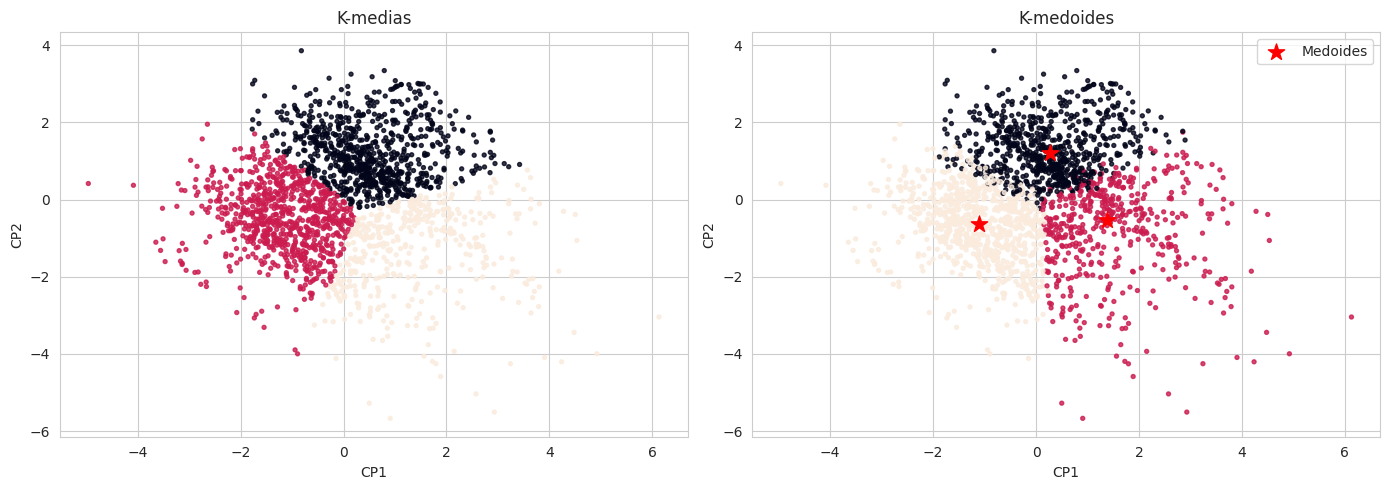

In [ ]:
# K-medias vs. K-medoides en la misma muestra
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(muestra["CP1"], muestra["CP2"], c=muestra["kmeans"], alpha=0.8, s=8)
axes[0].set_title("K-medias")
axes[1].scatter(muestra["CP1"], muestra["CP2"], c=muestra["kmedoides"], alpha=0.8, s=8)
med = muestra.iloc[Kmedoides.medoid_indices_]
axes[1].scatter(med["CP1"], med["CP2"], color="red", s=150, marker="*", label="Medoides")
axes[1].legend(); axes[1].set_title("K-medoides")
for ax in axes: ax.set_xlabel("CP1"); ax.set_ylabel("CP2")
plt.tight_layout(); plt.show()

Los tres representantes son máquinas reales de la base, y ninguna falló: son máquinas "típicas" de su grupo, como se espera de un representante. Corresponden a los mismos regímenes de K-medias:
- Uno **caliente** (301,5 K, 1.459 rpm).
- Uno **rápido** (1.697 rpm, torque de 30 Nm).
- Uno **frío** (298,4 K).

En la gráfica, las estrellas rojas son los medoides.

### 8.2 ¿K-medoides coincide con K-medias?
Usamos el **Índice de Rand Ajustado (ARI)**, que mide cuánto coinciden dos agrupaciones: 1 = idénticas, 0 = como al azar

In [ ]:
# ¿K-medoides y K-medias encuentran los mismos grupos? Comparamos en la misma muestra.
ari = adjusted_rand_score(muestra["kmeans"], muestra["kmedoides"])
print(f"Índice de Rand ajustado (ARI) entre K-medias y K-medoides: {ari:.2f}")
print("(1 = grupos idénticos, 0 = coincidencia al azar)\n")
pd.crosstab(muestra["kmeans"], muestra["kmedoides"], rownames=["K-medias"], colnames=["K-medoides"])

Índice de Rand ajustado (ARI) entre K-medias y K-medoides: 0.70
(1 = grupos idénticos, 0 = coincidencia al azar)



K-medoides,0,1,2
K-medias,,,
0,645,115,9
1,57,5,749
2,0,372,48


ARI = **0,70**: los dos métodos coinciden en buena medida. En la tabla cruzada, cada grupo de K-medias corresponde mayoritariamente a un grupo de K-medoides. En conclusión, los regímenes son estables, no dependen del método.


## 9. DBSCAN: las máquinas que operan fuera de lo normal

DBSCAN agrupa según la densidad: un clúster es una zona donde hay muchos puntos juntos. Usa dos parámetros:
- **`eps`:** el radio del "vecindario" de cada punto.
- **`min_samples`:** cuántos vecinos se necesitan dentro de ese radio para ser un punto "núcleo".

Los puntos que no tienen suficientes vecinos y no son alcanzables desde ningún núcleo se marcan como ruido (etiqueta −1). Esos son nuestros candidatos a anomalía.





### 9.1 Elegir `min_samples` y `eps`

Los dos parámetros dependen uno del otro, así que los elegimos juntos:
1. Para cada valor de `min_samples`, calculamos la distancia de cada punto a su vecino número `min_samples` con `NearestNeighbors`.
2. Ordenamos esas distancias y buscamos el codo con `KneeLocator`. Ese valor es `eps`.


In [ ]:
# min_samples: probamos varios valores. Para cada uno, eps sale del codo del gráfico
# de k-distancias, usando la distancia al vecino número min_samples.
def eps_por_codo(min_samples):
    neigh = NearestNeighbors(n_neighbors=min_samples)
    nbrs = neigh.fit(Z)
    distancias, indices = nbrs.kneighbors(Z)
    distancias = np.sort(distancias[:, -1])        # distancia al vecino número min_samples
    i = np.arange(len(distancias))
    knee = KneeLocator(i, distancias, S=1, curve="convex", direction="increasing", interp_method="polynomial")
    return round(float(distancias[knee.knee]), 2), distancias

filas = []
for ms in [5, 10, 20]:
    e, _ = eps_por_codo(ms)
    etiquetas = DBSCAN(eps=e, min_samples=ms).fit(Z).labels_
    filas.append({"min_samples": ms, "eps (codo)": e,
                  "clústeres": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
                  "% ruido": round((etiquetas == -1).mean() * 100, 1)})
pd.DataFrame(filas)

,min_samples,eps (codo),clústeres,% ruido
0,5,0.50,9,5.1
1,10,0.60,2,4.3
2,20,0.72,1,3.8


**¿Qué vemos?**
- Con `min_samples` pequeño (5), DBSCAN es "fácil de complacer": forma 9 clústeres, varios de ellos diminutos.
- Con 10 o 20, encuentra uno o dos clústeres y marca como ruido un 4%. El resultado es estable entre 10 y 20.

Escogemos **`min_samples = 10`**, siguiendo la regla práctica de la literatura de DBSCAN (2 × número de variables = 2 × 5). Es un valor que da resultados estables.

min_samples: 10 | eps sugerido por el codo: 0.6


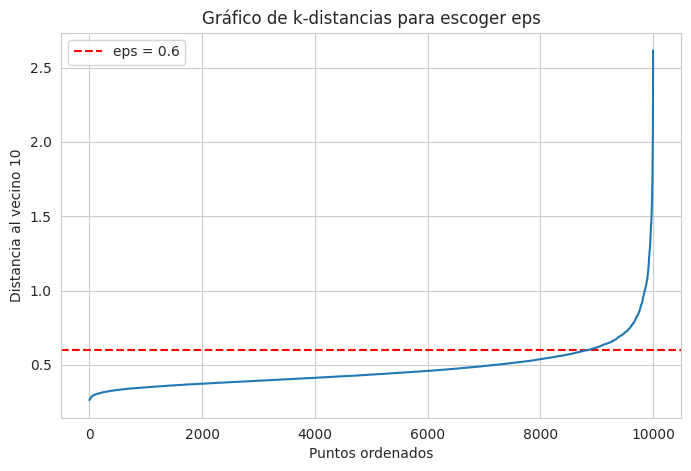

In [ ]:
# Elegimos min_samples = 2 x número de variables (regla práctica de la literatura de DBSCAN)
MIN_SAMPLES = 2 * len(variables)
EPS, distancias = eps_por_codo(MIN_SAMPLES)
print("min_samples:", MIN_SAMPLES, "| eps sugerido por el codo:", EPS)

fig = plt.figure(figsize=(8, 5))
plt.axhline(y=EPS, color="r", linestyle="--", label=f"eps = {EPS}")
plt.plot(distancias)
plt.xlabel("Puntos ordenados"); plt.ylabel(f"Distancia al vecino {MIN_SAMPLES}")
plt.title("Gráfico de k-distancias para escoger eps"); plt.legend()
plt.show()



```
# Esto tiene formato de código
```

La curva sube despacio y, al final, **se dispara**: esos son los puntos aislados. El codo está en **eps ≈ 0,6**.



### 9.2 Modelo DBSCAN

In [ ]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z)
clusteres = db.labels_
n_clusteres = len(set(clusteres)) - (1 if -1 in clusteres else 0)
df["dbscan"] = clusteres
df["ruido_dbscan"] = (clusteres == -1).astype(int)

print("Clústeres encontrados (sin contar el ruido):", n_clusteres)
print("Puntos marcados como ruido (-1):", df["ruido_dbscan"].sum())
print("\nTamaño de cada clúster:")
print(pd.Series(clusteres).value_counts().sort_index())
perfil("ruido_dbscan")

Clústeres encontrados (sin contar el ruido): 2
Puntos marcados como ruido (-1): 432

Tamaño de cada clúster:
-1     432
 0    9556
 1      12
Name: count, dtype: int64


,n,temp_aire,temp_proceso,velocidad_rpm,torque,desgaste_min,fallas,tasa_falla_pct,veces_el_promedio
ruido_dbscan,,,,,,,,,
0,9568,300.0,310.0,1523.3,40.3,107.9,237,2.5,0.7
1,432,299.9,309.8,1881.2,32.2,109.7,102,23.6,7.0


In [ ]:
# ¿Qué tipo de fallas quedaron dentro del ruido?
pd.DataFrame({"total": df[tipos_falla].sum(),
              "en el ruido": df.loc[df["ruido_dbscan"] == 1, tipos_falla].sum(),
              "% detectado": (df.loc[df["ruido_dbscan"] == 1, tipos_falla].sum() / df[tipos_falla].sum() * 100).round(0)})

,total,en el ruido,% detectado
falla_desgaste,46,6,13.0
falla_calor,115,12,10.0
falla_potencia,95,75,79.0
falla_sobreesfuerzo,98,26,27.0
falla_aleatoria,19,0,0.0


- **Potencia:** DBSCAN detecta el 79% (75 de 95). Son las fallas en valores extremos de velocidad o torque, justo los puntos más aislados.
- **Sobreesfuerzo:** 27%, desgaste: 13% y calor: 10%. Estas fallas ocurren en combinaciones de valores que, por separado, son normales. Por ejemplo, una temperatura alta y una velocidad baja son comunes; lo peligroso es tenerlas juntas. Por eso esos puntos no quedan "aislados".
- **Aleatoria:** 0%. Era de esperarse: son fallas al azar, que no dependen de las variables. Es una buena señal de que el método no está "inventando".

### 9.3 ¿Qué pasa si movemos `eps`?
Probamos varios valores de `eps` (el ruido aparece en negro):

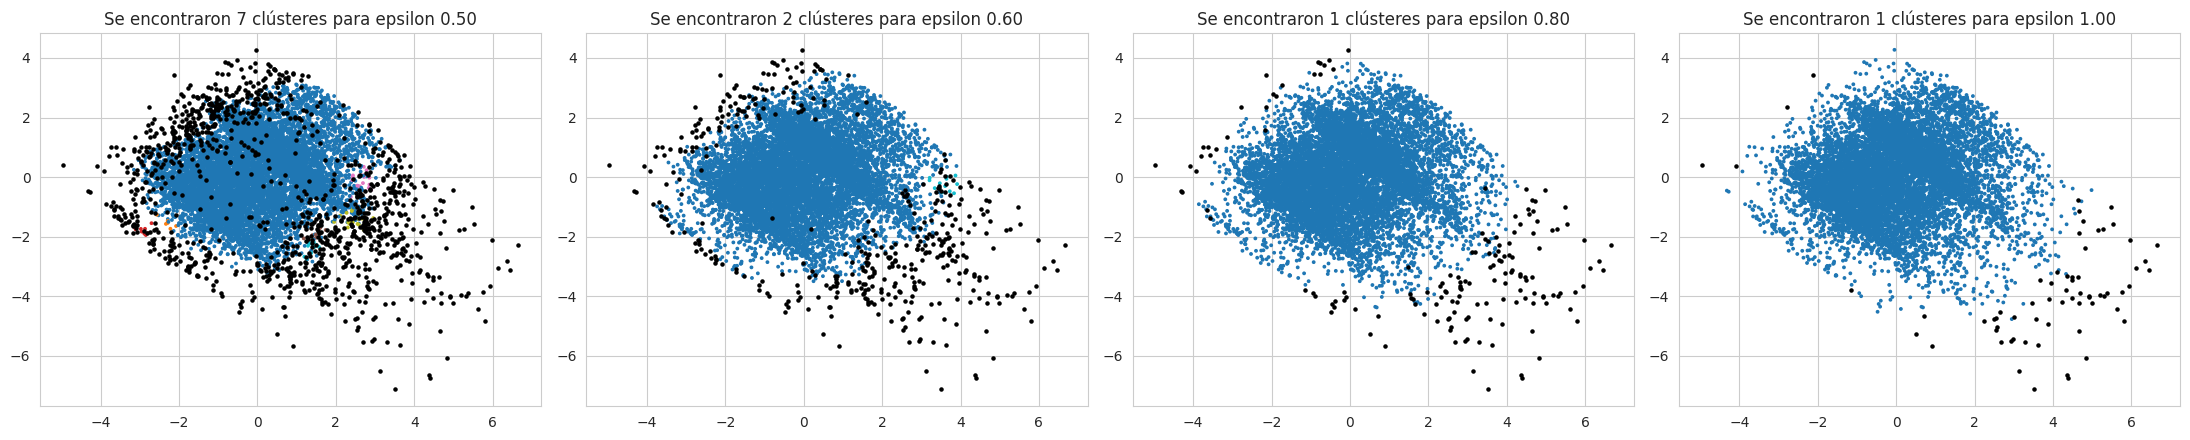

,eps,clústeres,puntos_ruido,% del total,tasa_falla_en_ruido_%,% de fallas detectadas
0,0.5,7,1161,11.6,14.8,50.7
1,0.6,2,432,4.3,23.6,30.1
2,0.8,1,156,1.6,35.3,16.2
3,1.0,1,66,0.7,50.0,9.7


In [ ]:
import matplotlib.pyplot as plt

# Variación del valor de  eps: Más pequeño = más estricto = más ruido.
filas = []
fig, axs = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, e in zip(axs, [0.5, EPS, 0.8, 1.0]):
    clusteres_e = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit(Z).labels_
    n_cl = len(set(clusteres_e)) - (1 if -1 in clusteres_e else 0)
    ruido = clusteres_e == -1
    ax.scatter(df.loc[~ruido, "CP1"], df.loc[~ruido, "CP2"], c=clusteres_e[~ruido], s=3, cmap="tab10")
    ax.scatter(df.loc[ruido, "CP1"], df.loc[ruido, "CP2"], c="black", s=5)
    ax.set_title("Se encontraron %d clústeres para epsilon %0.2f" % (n_cl, e))
    filas.append({"eps": e, "clústeres": n_cl,
                  "puntos_ruido": ruido.sum(),
                  "% del total": round(ruido.mean() * 100, 1),
                  "tasa_falla_en_ruido_%": round(df.loc[ruido, "falla"].mean() * 100, 1),
                  "% de fallas detectadas": round(df.loc[ruido, "falla"].sum() / df["falla"].sum() * 100, 1)})
plt.tight_layout(); plt.show()
pd.DataFrame(filas)

Hay un intercambio (*trade-off*) entre precisión y cobertura:
- Con eps pequeño (0,5), DBSCAN es muy exigente: marca el 11,6% como ruido y forma 7 clústeres. Encuentra la mitad de las fallas (51%), pero solo el 15% de los marcados falla.
- Con eps = 0,6 (el codo), marca el 4,3%, con 24% de fallas, y encuentra el 30% de ellas.
- Con eps grande (1,0), es muy permisivo: solo marca el 0,7%, pero la mitad son fallas.

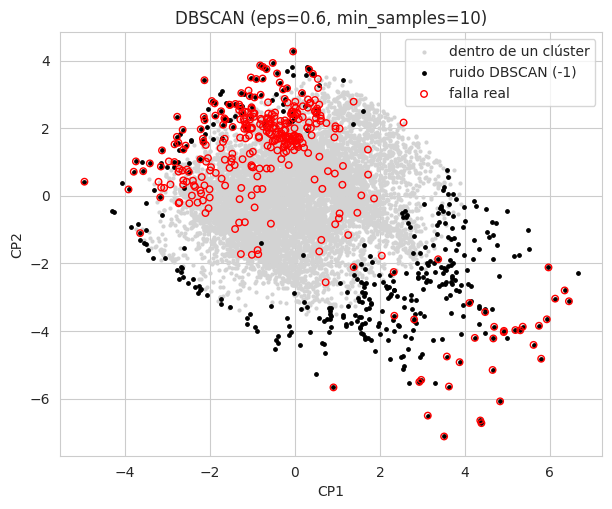

In [ ]:
normales = df[df["ruido_dbscan"] == 0]; ruido = df[df["ruido_dbscan"] == 1]
plt.figure(figsize=(7, 5.5))
plt.scatter(normales["CP1"], normales["CP2"], s=4, c="lightgray", label="dentro de un clúster")
plt.scatter(ruido["CP1"], ruido["CP2"], s=6, c="black", label="ruido DBSCAN (-1)")
f = df[df["falla"] == 1]
plt.scatter(f["CP1"], f["CP2"], s=22, facecolors="none", edgecolors="red", label="falla real")
plt.xlabel("CP1"); plt.ylabel("CP2"); plt.legend()
plt.title(f"DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})")
plt.show()

El ruido de DBSCAN (negro) está en las orillas de la nube:
- Abajo a la derecha (velocidad extrema y torque bajo) atrapa casi todas las fallas de potencia.
- En el borde izquierdo y superior (torque alto o temperatura alta) atrapa algunas fallas de sobreesfuerzo y calor.
- Las fallas que están dentro de la nube (gris) no se detectan, porque ocurren en condiciones que, vistas por separado, son normales.

## 10. Comparación de métodos

Para comparar, imaginemos que cada método le dice a la fábrica "revise estas máquinas". Medimos:
- % de máquinas señaladas: cuánto trabajo de revisión implica.
- Tasa de falla en las señaladas: de las que se revisan, cuántas sí tenían falla (precisión).
- Veces el promedio: cuánto mejor es que revisar al azar (3,4%).
- % de fallas detectadas: de todas las fallas, cuántas se encontraron (cobertura).

In [ ]:
tasa_base = df["falla"].mean()
total_fallas = df["falla"].sum()

def resumen(nombre, marcados):
    marcados = np.asarray(marcados, dtype=bool)
    return {"método": nombre,
            "% de máquinas señaladas": round(marcados.mean() * 100, 1),
            "tasa de falla en señaladas %": round(df.loc[marcados, "falla"].mean() * 100, 1),
            "veces el promedio": round(df.loc[marcados, "falla"].mean() / tasa_base, 1),
            "% de fallas detectadas": round(df.loc[marcados, "falla"].sum() / total_fallas * 100, 1)}

grupo_riesgo_k3 = perfil("kmeans")["tasa_falla_pct"].idxmax()
grupo_riesgo_k6 = perfil("kmeans6")["tasa_falla_pct"].idxmax()
comparacion = pd.DataFrame([
    resumen("Revisar todas (referencia)", np.ones(len(df))),
    resumen("K-medias K=3: grupo más riesgoso", df["kmeans"] == grupo_riesgo_k3),
    resumen("K-medias K=6: grupo más riesgoso", df["kmeans6"] == grupo_riesgo_k6),
    resumen(f"DBSCAN: ruido (eps={EPS})", df["ruido_dbscan"] == 1),
])
comparacion

,método,% de máquinas señaladas,tasa de falla en señaladas %,veces el promedio,% de fallas detectadas
0,Revisar todas (referencia),100.0,3.4,1.0,100.0
1,K-medias K=3: grupo más riesgoso,39.3,5.2,1.5,60.8
2,K-medias K=6: grupo más riesgoso,21.2,6.3,1.9,39.2
3,DBSCAN: ruido (eps=0.6),4.3,23.6,7.0,30.1


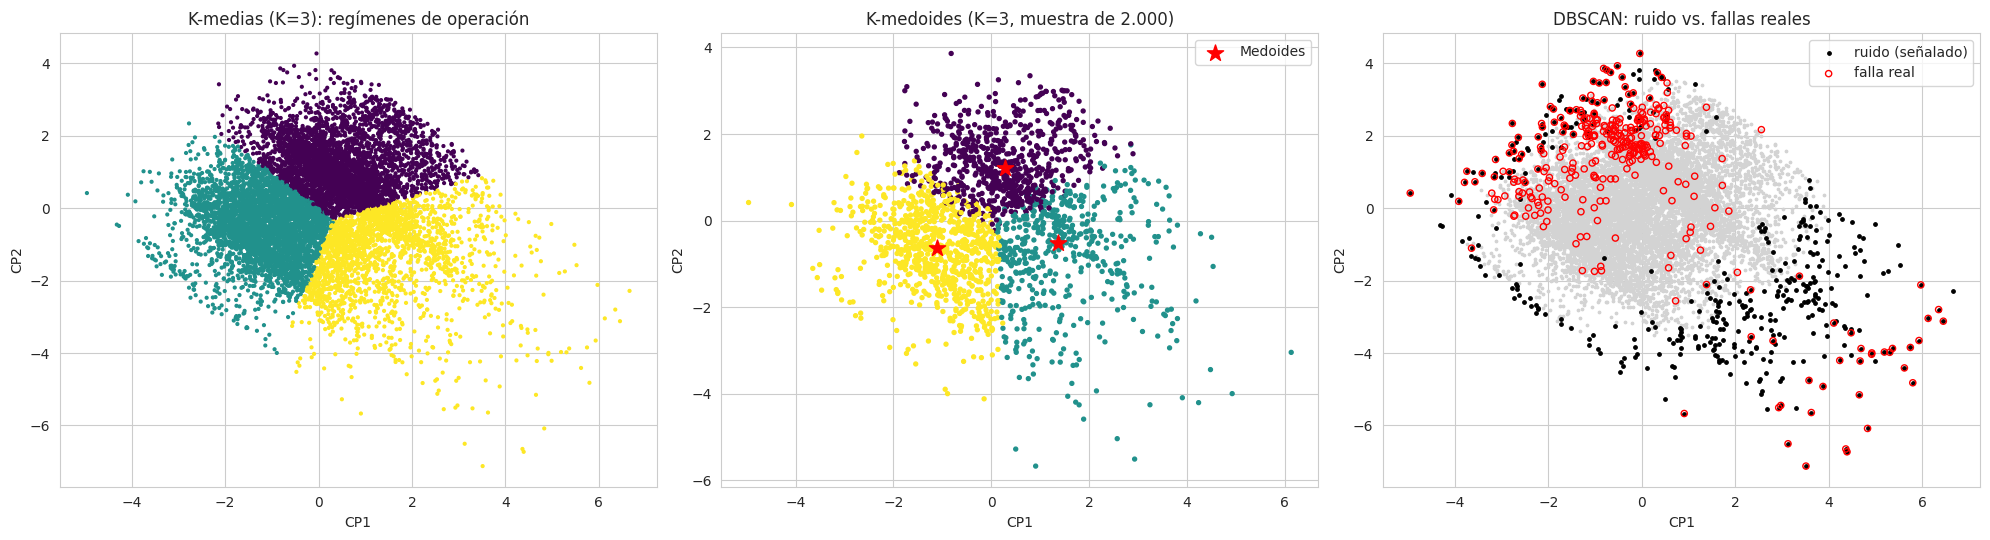

In [ ]:
# Visualización final
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5))
axs[0].scatter(df["CP1"], df["CP2"], c=df["kmeans"], s=4, cmap="viridis")
axs[0].set_title(f"K-medias (K={K}): regímenes de operación")
axs[1].scatter(muestra["CP1"], muestra["CP2"], c=muestra["kmedoides"], s=8, cmap="viridis")
med = muestra.iloc[Kmedoides.medoid_indices_]
axs[1].scatter(med["CP1"], med["CP2"], color="red", s=150, marker="*", label="Medoides")
axs[1].legend(); axs[1].set_title(f"K-medoides (K={K}, muestra de 2.000)")
n = df[df["ruido_dbscan"] == 0]; r = df[df["ruido_dbscan"] == 1]; f = df[df["falla"] == 1]
axs[2].scatter(n["CP1"], n["CP2"], s=3, c="lightgray")
axs[2].scatter(r["CP1"], r["CP2"], s=6, c="black", label="ruido (señalado)")
axs[2].scatter(f["CP1"], f["CP2"], s=20, facecolors="none", edgecolors="red", label="falla real")
axs[2].legend(); axs[2].set_title("DBSCAN: ruido vs. fallas reales")
for ax in axs: ax.set_xlabel("CP1"); ax.set_ylabel("CP2")
plt.tight_layout(); plt.show()

- **Revisar al azar:** solo 3,4% de lo revisado tiene falla.
- **K-medias:** sirve para describir la máquina y entender sus regímenes, pero como detector es débil. Su grupo más riesgoso tiene menos de 2 veces el promedio, porque los grupos son muy grandes (21–39% de las máquinas).
- **K-medoides:** encuentra los mismos regímenes que K-medias (ARI 0,70) y nos da máquinas reales como representantes de cada régimen. Confirma que los grupos no dependen del método.
- **DBSCAN (ruido):** el mejor detector. Revisando solo el 4,3% de las máquinas, el 24% tiene falla (7 veces el promedio) y se encuentra el 30% de todas las fallas. Moviendo `eps` se puede revisar más (y encontrar más) o menos (y acertar más).

**Cada método tiene un papel distinto:**
- **PCA:** entender y visualizar.
- **K-medias y K-medoides:** segmentar en regímenes de operación (descriptivo).
- **DBSCAN:** detectar anomalías (alerta temprana).

## 11. La solución para el negocio: semáforo de mantenimiento preventivo

Hasta aquí entendimos la máquina. Ahora convertimos eso en algo que el jefe de mantenimiento pueda usar en sus labores: una lista priorizada de máquinas para revisar antes de que fallen, con qué revisar en cada una.

Todo se construye sin mirar las fallas:
1. **Nivel de prioridad (semáforo)**, con DBSCAN:
   - 🔴 **ROJO:** la máquina está muy aislada. Sigue siendo "ruido" incluso con un radio grande (eps = 1,0): opera en condiciones extremas. *Revisar de inmediato.*
   - 🟡 **AMARILLO:** la máquina está aislada (ruido con el eps del codo, 0,6). *Programar revisión*.
   - 🟢 **VERDE:** opera dentro del grupo normal. Mantenimiento de rutina.
2. **Qué revisar:** miramos cuál variable de la máquina está más fuera de lo normal y la traducimos a una acción de mantenimiento.
3. **Contexto:** el régimen de operación de K-medias (caliente, frío o rápido) y el consumo de energía (potencia = torque × velocidad).

In [ ]:
# NIVEL DE PRIORIDAD (semáforo) usando solo DBSCAN, sin mirar las fallas:
#  - ROJO: la máquina es "ruido" incluso con un radio grande (eps = 1,0) -> está MUY aislada
#  - AMARILLO: es "ruido" con el radio elegido por el codo (eps = EPS) -> está aislada
#  - VERDE: pertenece al grupo grande -> opera en condiciones normales
EPS_ROJO = 1.0
etiquetas_rojo = DBSCAN(eps=EPS_ROJO, min_samples=MIN_SAMPLES).fit(Z).labels_
df["prioridad"] = np.where(etiquetas_rojo == -1, "1. ROJO",
                  np.where(df["ruido_dbscan"] == 1, "2. AMARILLO", "3. VERDE"))
df["prioridad"].value_counts().sort_index()

,count
prioridad,
1. ROJO,66
2. AMARILLO,366
3. VERDE,9568


De 10.000 registros, el semáforo pone 66 en rojo, 366 en amarillo y 9.568 en verde. En total, el equipo de mantenimiento solo tiene que mirar 432 máquinas (4,3%).



### 11.1 ¿Qué revisar en cada máquina?

In [ ]:
# ¿QUÉ REVISAR? Para cada máquina miramos cuál variable está más "fuera de lo normal"
# (el valor estandarizado z más extremo) y la traducimos a una acción de mantenimiento.
def accion_sugerida(z):
    desvios = {
        "Revisar refrigeración (temperatura alta)": max(z["temp_aire"], z["temp_proceso"]),
        "Ajustar velocidad (potencia baja)": max(z["velocidad_rpm"], -z["torque"]),
        "Reducir carga (sobrecarga, alto consumo)": max(z["torque"], -z["velocidad_rpm"]),
        "Cambiar herramienta (desgaste alto)": z["desgaste_min"],
    }
    return max(desvios, key=desvios.get)

df["accion_sugerida"] = Z.apply(accion_sugerida, axis=1)

# La potencia (torque x velocidad) es la energía que consume la máquina; la mostramos en el reporte
df["potencia_W"] = (df["torque"] * df["velocidad_rpm"] * 2 * np.pi / 60).round(0)

# Nombre del régimen de operación de K-medias (según el perfil de cada grupo, sin mirar fallas)
perfil_z = Z.groupby(df["kmeans"]).mean()
def nombre_regimen(fila):
    temp = (fila["temp_aire"] + fila["temp_proceso"]) / 2
    if fila["velocidad_rpm"] > abs(temp):
        return "Rápido / poca fuerza"
    return "Caliente" if temp > 0 else "Frío"
df["regimen"] = df["kmeans"].map(perfil_z.apply(nombre_regimen, axis=1))

pd.crosstab(df.loc[df["prioridad"] != "3. VERDE", "accion_sugerida"],
            df.loc[df["prioridad"] != "3. VERDE", "prioridad"], margins=True, margins_name="Total")

prioridad,1. ROJO,2. AMARILLO,Total
accion_sugerida,,,
Ajustar velocidad (potencia baja),61,217,278
Cambiar herramienta (desgaste alto),1,25,26
"Reducir carga (sobrecarga, alto consumo)",4,110,114
Revisar refrigeración (temperatura alta),0,14,14
Total,66,366,432


Las acciones se reparten así:
- **Ajustar velocidad (potencia baja):** 278 máquinas. Giran muy rápido, casi sin hacer fuerza, y consumen poca energía. Son la mayoría de las rojas (61 de 66).
- **Reducir carga (sobrecarga, alto consumo):** 114. Hacen mucha fuerza y consumen mucha energía.
- **Cambiar herramienta (desgaste alto):** 26 máquinas.
- **Revisar refrigeración (temperatura alta):** 14 máquinas.

### 11.2 El entregable: lista priorizada de mantenimiento
Esta es la tabla que recibiría el jefe de planta. Está ordenada por prioridad y, dentro de cada nivel, por rareza (qué tan lejos está la máquina de sus vecinas; más alto = más anormal):

In [ ]:
# EL ENTREGABLE PARA EL JEFE DE MANTENIMIENTO: lista priorizada de máquinas a revisar
# (ordenadas de la más aislada a la menos aislada, usando la distancia a su vecino número 10)
df["rareza"] = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1].round(2)

pd.set_option("display.max_colwidth", None)   # para ver la acción completa
lista_mantenimiento = (df[df["prioridad"] != "3. VERDE"]
                       .sort_values(["prioridad", "rareza"], ascending=[True, False])
                       [["id", "id_producto", "prioridad", "rareza", "regimen", "temp_proceso",
                         "velocidad_rpm", "torque", "potencia_W", "desgaste_min", "accion_sugerida"]])
print("Máquinas en la lista de mantenimiento preventivo:", len(lista_mantenimiento))
lista_mantenimiento.head(15)

Máquinas en la lista de mantenimiento preventivo: 432


,id,id_producto,prioridad,rareza,regimen,temp_proceso,velocidad_rpm,torque,potencia_W,desgaste_min,accion_sugerida
847,848,L48027,1. ROJO,2.62,Rápido / poca fuerza,307.4,2833,5.6,1661.0,213,Ajustar velocidad (potencia baja)
5152,5153,L52332,1. ROJO,2.41,Rápido / poca fuerza,313.5,2643,12.7,3515.0,21,Ajustar velocidad (potencia baja)
4296,4297,L51476,1. ROJO,2.34,Rápido / poca fuerza,310.2,2825,5.8,1716.0,215,Ajustar velocidad (potencia baja)
1784,1785,L48964,1. ROJO,2.33,Rápido / poca fuerza,308.0,2886,3.8,1148.0,57,Ajustar velocidad (potencia baja)
50,51,L47230,1. ROJO,2.05,Rápido / poca fuerza,309.1,2861,4.6,1378.0,143,Ajustar velocidad (potencia baja)
1095,1096,L48275,1. ROJO,2.05,Rápido / poca fuerza,307.5,2721,9.3,2650.0,18,Ajustar velocidad (potencia baja)
463,464,L47643,1. ROJO,2.04,Rápido / poca fuerza,308.7,2874,4.2,1264.0,118,Ajustar velocidad (potencia baja)
4997,4998,M19857,1. ROJO,2.00,Rápido / poca fuerza,312.8,2659,11.4,3174.0,26,Ajustar velocidad (potencia baja)
4988,4989,L52168,1. ROJO,1.95,Rápido / poca fuerza,313.1,2497,13.0,3399.0,5,Ajustar velocidad (potencia baja)
880,881,M15740,1. ROJO,1.90,Frío,306.3,1235,76.2,9855.0,89,"Reducir carga (sobrecarga, alto consumo)"


**¿Cómo la usaría el jefe de mantenimiento?**
- Ve que la máquina 848 está en rojo: gira a 2.833 rpm con apenas 5,6 Nm de torque, consume solo 1.661 W (lo normal es ~6.300 W) y su herramienta lleva 213 minutos de uso.
- **Acción:** ajustar la velocidad lo antes posible, antes de que se detenga y pare la línea de producción.
- Así, en lugar de esperar a que algo se dañe (mantenimiento correctivo), la empresa programa la intervención (mantenimiento preventivo) y evita paradas no planeadas.



### 11.3 Validación: ¿el semáforo funciona?
Para comprobar si las máquinas señaladas eran las que estaban en riesgo, comparamos las máquinas con fallas reales con las obtenidas con el modelo:

In [ ]:
# VALIDACIÓN
validacion = df.groupby("prioridad").agg(
    maquinas=("falla", "size"),
    fallas_reales=("falla", "sum"),
    tasa_falla_pct=("falla", "mean"))
validacion["tasa_falla_pct"] = (validacion["tasa_falla_pct"] * 100).round(1)
validacion["veces_el_promedio"] = (validacion["tasa_falla_pct"] / (df["falla"].mean() * 100)).round(1)
validacion["% de todas las fallas"] = (validacion["fallas_reales"] / df["falla"].sum() * 100).round(1)
validacion

,maquinas,fallas_reales,tasa_falla_pct,veces_el_promedio,% de todas las fallas
prioridad,,,,,
1. ROJO,66,33,50.0,14.7,9.7
2. AMARILLO,366,69,18.9,5.6,20.4
3. VERDE,9568,237,2.5,0.7,69.9


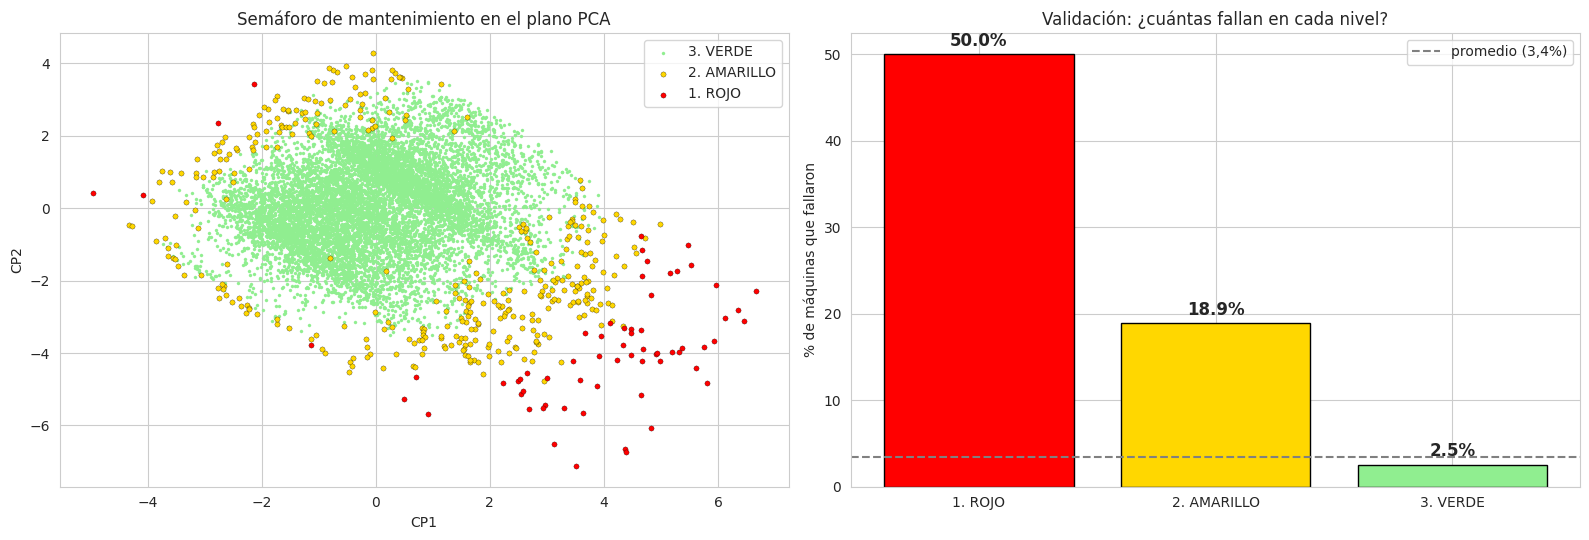

In [ ]:
colores_sem = {"1. ROJO": "red", "2. AMARILLO": "gold", "3. VERDE": "lightgreen"}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for nivel in ["3. VERDE", "2. AMARILLO", "1. ROJO"]:
    sub = df[df["prioridad"] == nivel]
    axes[0].scatter(sub["CP1"], sub["CP2"], s=5 if nivel == "3. VERDE" else 14,
                    c=colores_sem[nivel], label=nivel, edgecolor="k" if nivel != "3. VERDE" else None, linewidth=0.2)
axes[0].legend(); axes[0].set_xlabel("CP1"); axes[0].set_ylabel("CP2")
axes[0].set_title("Semáforo de mantenimiento en el plano PCA")

v = validacion.reset_index()
axes[1].bar(v["prioridad"], v["tasa_falla_pct"], color=[colores_sem[p] for p in v["prioridad"]], edgecolor="k")
axes[1].axhline(df["falla"].mean() * 100, ls="--", color="gray", label="promedio (3,4%)")
for i, t in enumerate(v["tasa_falla_pct"]):
    axes[1].text(i, t + 1, f"{t}%", ha="center", fontsize=12, fontweight="bold")
axes[1].set_ylabel("% de máquinas que fallaron"); axes[1].legend()
axes[1].set_title("Validación: ¿cuántas fallan en cada nivel?")
plt.tight_layout(); plt.show()

Cada nivel tiene un riesgo muy distinto:
- 🔴 **ROJO:** la mitad (50%) falla: 14,7 veces más que el promedio.
- 🟡 **AMARILLO:** falla el 19%: 5,6 veces más que el promedio.
- 🟢 **VERDE:** falla solo el 2,5%, por debajo del promedio.

Revisando solo el 4,3% de las máquinas (rojo + amarillo) se anticipa el 30% de todas las fallas (102 de 339).



Miramos las máquinas señaladas que sí fallaron:



In [ ]:
# Acción sugerida corresponde al tipo de falla real - sólo máquinas señaladas que fallaron.
señaladas = df[(df["prioridad"] != "3. VERDE") & (df["falla"] == 1)]
pd.crosstab(señaladas["accion_sugerida"], señaladas["tipo_falla"])

tipo_falla,calor,desgaste,potencia,sobreesfuerzo
accion_sugerida,,,,
Ajustar velocidad (potencia baja),0,3,31,0
Cambiar herramienta (desgaste alto),1,2,0,2
"Reducir carga (sobrecarga, alto consumo)",11,1,41,9
Revisar refrigeración (temperatura alta),0,0,0,1



En general, la acción apunta al problema correcto:
- **"Ajustar velocidad (potencia baja)"** → 31 fallas de **potencia**: la máquina falló justamente por trabajar con muy poca potencia.
- **"Reducir carga (sobrecarga)"** → 41 fallas de potencia (por exceso), 11 de calor y 9 de sobreesfuerzo, todas relacionadas con trabajar con demasiada fuerza.

### 11.4 ¿Cuánto podría ahorrar la empresa? (ejemplo ilustrativo)
Los costos reales dependen de cada empresa. Para mostrar la lógica, asumimos que revisar una máquina cuesta 1 unidad y que una falla no planeada (parada + reparación + producción perdida) cuesta 20 unidades.

In [ ]:
# EJEMPLO ILUSTRATIVO DE IMPACTO (los costos son SUPUESTOS para mostrar la lógica;
# cada empresa debe poner sus propios valores)
costo_revision = 1        # costo de revisar una máquina (en "unidades de costo")
costo_falla = 20          # costo de una falla no planeada: parada + reparación + producción perdida

n_revisadas = (df["prioridad"] != "3. VERDE").sum()
fallas_evitadas_semaforo = df.loc[df["prioridad"] != "3. VERDE", "falla"].sum()
fallas_evitadas_azar = round(n_revisadas * df["falla"].mean())   # si se revisaran las mismas al azar

for nombre, evitadas in [("Revisando al azar", fallas_evitadas_azar), ("Con el semáforo", fallas_evitadas_semaforo)]:
    ahorro = evitadas * costo_falla - n_revisadas * costo_revision
    print(f"{nombre}: se revisan {n_revisadas} máquinas, se anticipan {evitadas} fallas, "
          f"beneficio neto = {ahorro} unidades")

Revisando al azar: se revisan 432 máquinas, se anticipan 15 fallas, beneficio neto = -132 unidades
Con el semáforo: se revisan 432 máquinas, se anticipan 102 fallas, beneficio neto = 1608 unidades


Con el mismo esfuerzo (revisar 432 máquinas):
- **Al azar** se anticiparían unas 15 fallas, y la revisión costaría más de lo que ahorra.
- **Con el semáforo** se anticipan 102 fallas: casi 7 veces más, con un beneficio claramente positivo.

**Esta es la necesidad de negocio que resuelve el proyecto:** decirle a la empresa dónde poner su esfuerzo de mantenimiento para evitar paradas no planeadas, sin necesitar un historial de fallas.

## 12. Conclusiones

### Respuesta a la necesidad del negocio
Con un algoritmo de aprendizaje no supervisado, y sin necesitar un historial de fallas, construimos un semáforo que le dice al jefe de mantenimiento qué máquinas revisar primero y qué revisar en cada una.

- Revisando solo el 4,3% de las máquinas (rojo + amarillo) se anticipa el 30% de las fallas.
- En el nivel rojo, la mitad de las máquinas sí estaban por fallar: 14,7 veces más que el promedio.
- Con el mismo esfuerzo de revisión, el semáforo anticipa casi 7 veces más fallas que revisar al azar.

### Lo que aprendimos de los datos
1. La máquina falla en los extremos (EDA): con velocidad muy baja o muy alta, torque muy alto, herramienta muy gastada o temperatura alta. Cada tipo de falla tiene su "zona de peligro".
2. Las 5 variables se resumen en 3 ideas (PCA, 95% de la información): temperatura, mecánica (velocidad contra torque, es decir, consumo de energía) y desgaste.
3. La máquina opera en un continuo, no en grupos separados (Silhouette ~0,26). Aun así, K-medias y K-medoides encuentran regímenes de operación coherentes entre sí (ARI 0,70) y con riesgos distintos: las 115 fallas por calor quedaron todas en el régimen "caliente".
4. Las máquinas aisladas son las que fallan (DBSCAN): el ruido tiene 7 veces más fallas que el promedio.
5. La acción sugerida apunta al problema correcto: las máquinas marcadas como "potencia baja" o "sobrecarga" fallaron justamente por potencia o por sobreesfuerzo.
6. Los parámetros se eligieron sin mirar las fallas (Silhouette y el codo), por lo que el método se puede aplicar en una planta que no tenga historial.

### Limitaciones
- La base es sintética: en una fábrica real los datos tendrían más ruido y errores de sensor.
- El semáforo detecta muy bien las fallas por condiciones extremas (potencia), pero le cuesta más con las fallas por combinaciones de valores normales (calor, desgaste). Por eso el 70% de las fallas sigue en verde, y el mantenimiento de rutina no se debe eliminar.
- Los umbrales (eps) y los costos del ejemplo son decisiones del negocio: cada empresa los ajusta según cuántas máquinas puede revisar y cuánto le cuesta una parada.


Finalmente, sin decirle nunca a los algoritmos qué es una falla (aprendizaje supervisado), logramos señalar las máquinas en riesgo y qué revisar en cada una. Así la empresa pasa de reparar cuando la máquina ya se dañó (mantenimiento correctivo) a intervenir antes (mantenimiento preventivo), y evita paradas que le hacen perder dinero.